In [1]:
from matplotlib import pyplot as plt
from matplotlib import colors
import numpy as np
from matplotlib.patches import Path, PathPatch
import pandas as pd
from shapely.geometry import Point, shape, Polygon
from shapely.ops import unary_union, cascaded_union
from geopandas.tools import sjoin
import geopandas as gpd
from netCDF4 import Dataset
from cartopy import crs as ccrs
from cartopy.io.shapereader import Reader
from sklearn.metrics import mean_squared_error
import scipy.stats as st
from sklearn.linear_model import LinearRegression
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import FormatStrFormatter
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\3062881070.py:8: UserWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas will still use PyGEOS by default for now. To force to use and test Shapely 2.0, you have to set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In a future release, GeoPandas will switch to using Shapely by default. If you are using PyGEOS directly (calling PyGEOS functions on geometries from GeoPandas), this will then stop working and you are encouraged to migrate from PyGEOS to Shapely 2.0 (https://shapely.readthedocs.io/en/latest/migration_pygeos.html).
  from geopandas.tools import sjoin


<h1> Load Data

In [2]:
# CMAQ lat/lon datafile
d03 = Dataset('C:/Users/x12la/Desktop/latlon_ChicagoLADCO_d03.nc')
cmaq_lon,cmaq_lat = np.array(d03['lon']),np.array(d03['lat'])
cmaq_llat,cmaq_ulat,cmaq_llon,cmaq_ulon=cmaq_lat.min(), cmaq_lat.max(), cmaq_lon.min(), cmaq_lon.max()

In [3]:
#CMAP 7 counties surrounding Chicago/Cook County
cmap_cty = gpd.read_file('C:/Users/x12la/Desktop/Scripts/CMAP_cty.shp')
cmap_cty = cmap_cty.to_crs('EPSG:4326')

#primary roads
primary_roads = gpd.read_file('C:/Users/x12la/Desktop/Scripts/tl_2016_us_primaryroads.shp')
primary_roads = primary_roads.to_crs('EPSG:4326')

In [4]:
# Base scenario
base = {
    "Jan": gpd.read_file("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_Jan2023_avg.shp").to_crs("EPSG:4326"),
    "Apr": gpd.read_file("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_202304_D03_average.shp").to_crs("EPSG:4326"),
    "Jul": gpd.read_file("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_July2023_Average.shp").to_crs("EPSG:4326"),
    "Oct": gpd.read_file("../EmissionMod_CTMComp/COMBINE_ACONC_LOCUSIdling_HDVSpatial_202310_D03_average.shp").to_crs("EPSG:4326"),
}

# Base scenario mda8o3
base_o3 = {
    "Jan": gpd.read_file("../EmissionMod_CTMComp/MDA8O3_LOCUSIdling_HDVSpatial_202301.shp").to_crs("EPSG:4326"),
    "Apr": gpd.read_file("../EmissionMod_CTMComp/MDA8O3_Apr2023_LOCUSIdling_HDVSpatial_Average.shp").to_crs("EPSG:4326"),
    "Jul": gpd.read_file("../EmissionMod_CTMComp/MDA8O3_July2023_LOCUSIdling_HDVSpatial_Average.shp").to_crs("EPSG:4326"),
    "Oct": gpd.read_file("../EmissionMod_CTMComp/MDA8O3_Oct2023_LOCUSIdling_HDVSpatial_Average.shp").to_crs("EPSG:4326"),
}

In [5]:
# zeropre2010sscenario
zeropre2010s= {
    "Jan": gpd.read_file("COMBINE_ACONC_ZeroPre2010s_Jan2023_avg.shp").to_crs("EPSG:4326"),
    "Apr": gpd.read_file("COMBINE_ACONC_ZeroPre2010s_April2023_average.shp").to_crs("EPSG:4326"),
    "Jul": gpd.read_file("COMBINE_ACONC_ZeroPre2010s_July2023_average.shp").to_crs("EPSG:4326"),
    "Oct": gpd.read_file("COMBINE_ACONC_ZeroPre2010s_Oct2023_average.shp").to_crs("EPSG:4326"),
}

# zeropre2010sscenario mda8o3
zeropre2010s_o3 = {
    "Jan": gpd.read_file("MDA8O3_ZeroPre2010s_202301.shp").to_crs("EPSG:4326"),
    "Apr": gpd.read_file("MDA8O3_April2023_ZeroPre2010s_Average.shp").to_crs("EPSG:4326"),
    "Jul": gpd.read_file("MDA8O3_July2023_ZeroPre2010s_Average.shp").to_crs("EPSG:4326"),
    "Oct": gpd.read_file("MDA8O3_Oct2023_ZeroPre2010s_Average.shp").to_crs("EPSG:4326"),
}

In [7]:
#clip to cmap domain 
cmap_roads = gpd.clip(primary_roads, cmap_cty)

cmap_base = {month: gpd.clip(gdf, cmap_cty) for month, gdf in base.items()}
cmap_zeropre2010s= {month: gpd.clip(gdf, cmap_cty) for month, gdf in zeropre2010s.items()}

cmap_base_o3 = {month: gpd.clip(gdf, cmap_cty) for month, gdf in base_o3.items()}
cmap_zeropre2010s_o3 = {month: gpd.clip(gdf, cmap_cty) for month, gdf in zeropre2010s_o3.items()}

<h1> Plot Total Magnitude Pollutants  

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\150150410.py:36: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(plot_config[pol]["cmap_name"])(np.linspace(0, 1, N_BINS))


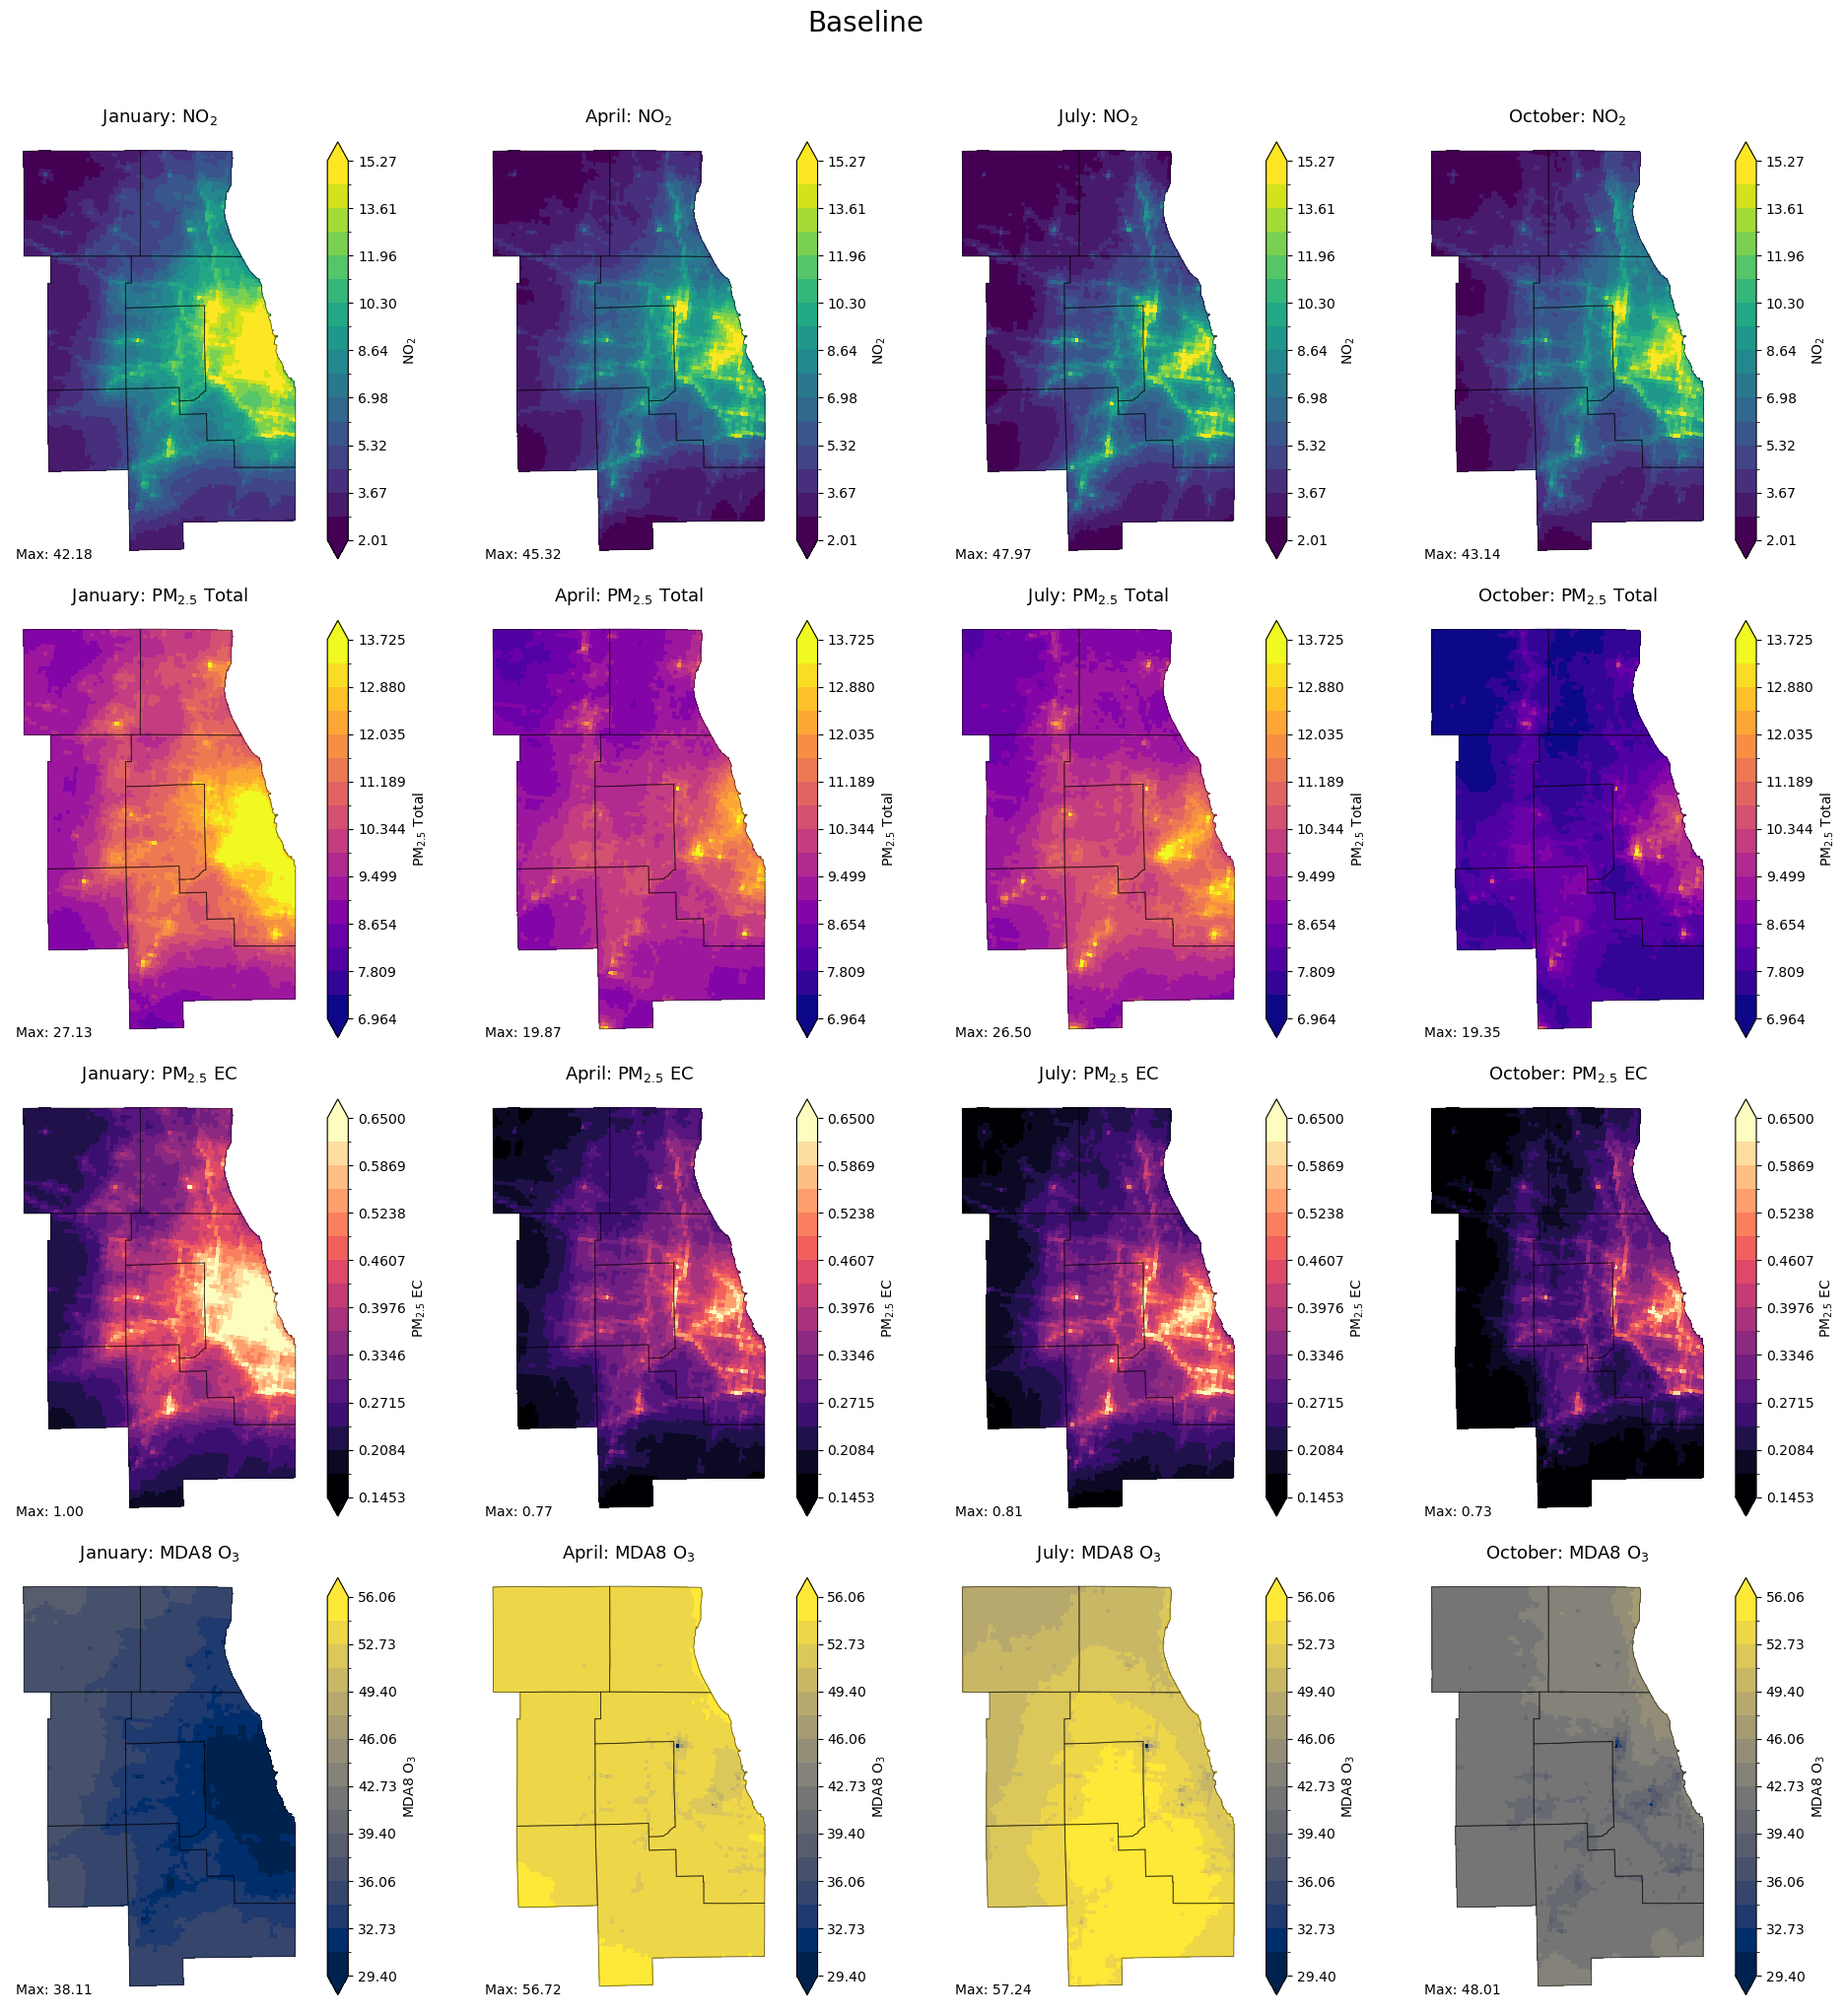

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\150150410.py:36: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(plot_config[pol]["cmap_name"])(np.linspace(0, 1, N_BINS))


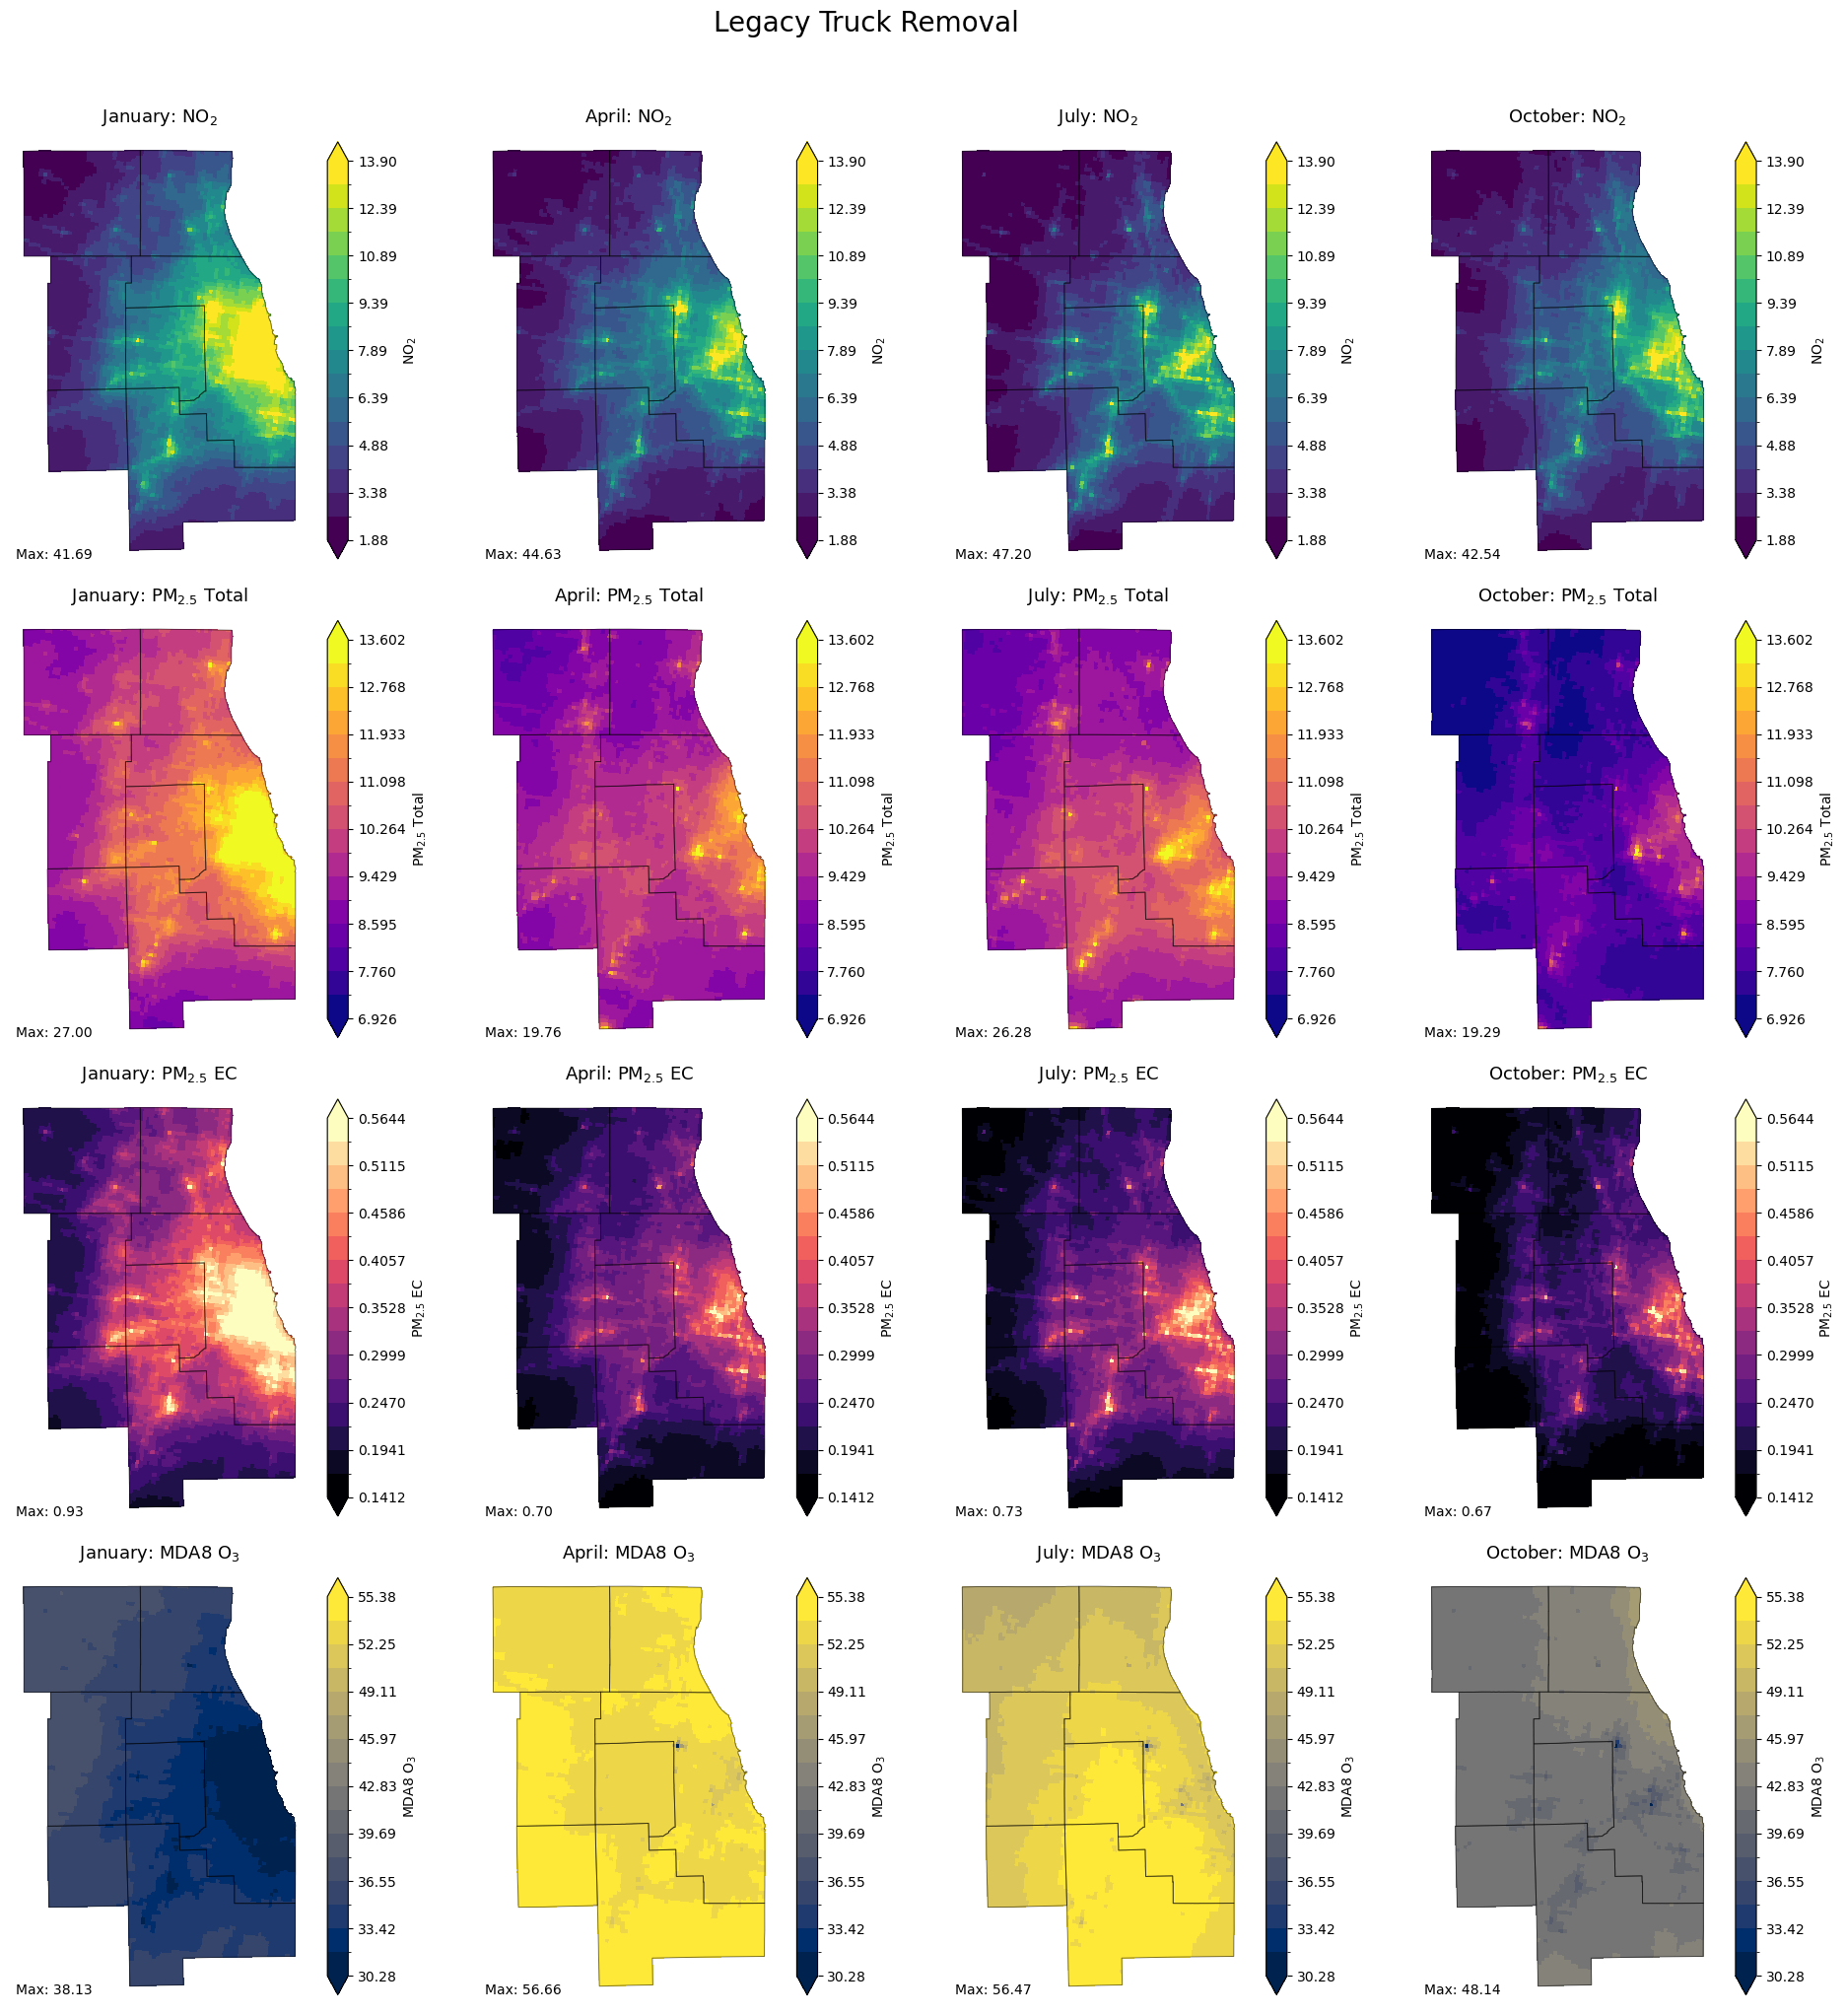

In [8]:
N_BINS = 16

plot_config = {
    "NO2": {"cmap_name": "viridis", "title": "NO$_2$", "label": "NO$_2$", "column": "NO2"},
    "PM25_TOT": {"cmap_name": "plasma", "title": "PM$_{2.5}$ Total", "label": "PM$_{2.5}$ Total", "column": "PM25_TOT"},
    "PM25_EC": {"cmap_name": "magma", "title": "PM$_{2.5}$ EC", "label": "PM$_{2.5}$ EC", "column": "PM25_EC"},
    "O3": {"cmap_name": "cividis", "title": "MDA8 O$_3$", "label": "MDA8 O$_3$", "column": "O3"},
}

pollutants = ["NO2", "PM25_TOT", "PM25_EC", "O3"]
months = ["Jan", "Apr", "Jul", "Oct"]
month_labels = ["January", "April", "July", "October"]

def plot_monthly_pollutants(scenario_gdfs_by_pol, figure_title):
    pollutant_styles = {}

    for pol in pollutants:
        vals_all = []
        col = plot_config[pol]["column"]

        for month in months:
            gdf = scenario_gdfs_by_pol[pol][month]
            vals = gdf[col].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            vals_all.append(vals)

        vals_all = np.concatenate(vals_all)

        vmin = np.quantile(vals_all, 0.01)
        vmax = np.quantile(vals_all, 0.99)

        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6

        cmap_disc = ListedColormap(
            plt.cm.get_cmap(plot_config[pol]["cmap_name"])(np.linspace(0, 1, N_BINS))
        )

        bounds = np.linspace(vmin, vmax, N_BINS + 1)
        norm = BoundaryNorm(bounds, cmap_disc.N)

        pollutant_styles[pol] = {
            "vmin": vmin,
            "vmax": vmax,
            "bounds": bounds,
            "cmap": cmap_disc,
            "norm": norm,
        }

    fig, axs = plt.subplots(
        nrows=4,
        ncols=4,
        figsize=(20, 20),
        subplot_kw={"projection": ccrs.PlateCarree()},
    )

    fig.suptitle(figure_title, fontsize=20, y=1.02)

    for i, pol in enumerate(pollutants):
        col = plot_config[pol]["column"]

        for j, month in enumerate(months):
            ax = axs[i, j]
            gdf = scenario_gdfs_by_pol[pol][month]

            style = pollutant_styles[pol]
            cmap_disc = style["cmap"]
            norm = style["norm"]
            bounds = style["bounds"]

            gdf.plot(
                column=col,
                ax=ax,
                cmap=cmap_disc,
                norm=norm,
                edgecolor="none",
                antialiased=False,
            )

            cmap_cty.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)

            ax.set_title(f"{month_labels[j]}: {plot_config[pol]['title']}", fontsize=13)
            ax.set_axis_off()

            sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
            sm._A = []

            cbar = fig.colorbar(
                sm,
                ax=ax,
                fraction=0.046,
                pad=0.04,
                boundaries=bounds,
                ticks=bounds[::2],
                spacing="proportional",
                extend="both",
            )

            cbar.set_label(plot_config[pol]["label"], fontsize=10)

            vals = gdf[col].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            vmax_panel = float(np.nanmax(vals))

            ax.text(
                0.02,
                0.02,
                f"Max: {vmax_panel:.2f}",
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=10,
                color="black",
                bbox=dict(facecolor="white", alpha=0.7, boxstyle="round,pad=0.25", linewidth=0),
            )

    plt.tight_layout()
    plt.show()

base_monthly_gdfs_by_pol = {
    "NO2": cmap_base,
    "PM25_TOT": cmap_base,
    "PM25_EC": cmap_base,
    "O3": cmap_base_o3,
}

zeropre2010s_monthly_gdfs_by_pol = {
    "NO2": cmap_zeropre2010s,
    "PM25_TOT": cmap_zeropre2010s,
    "PM25_EC": cmap_zeropre2010s,
    "O3": cmap_zeropre2010s_o3,
}

plot_monthly_pollutants(
    base_monthly_gdfs_by_pol,
    "Baseline",
)

plot_monthly_pollutants(
    zeropre2010s_monthly_gdfs_by_pol,
    "Legacy Truck Removal",
)

<h1> Plot Difference in Air Pollutants 

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:99: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:103: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.lins

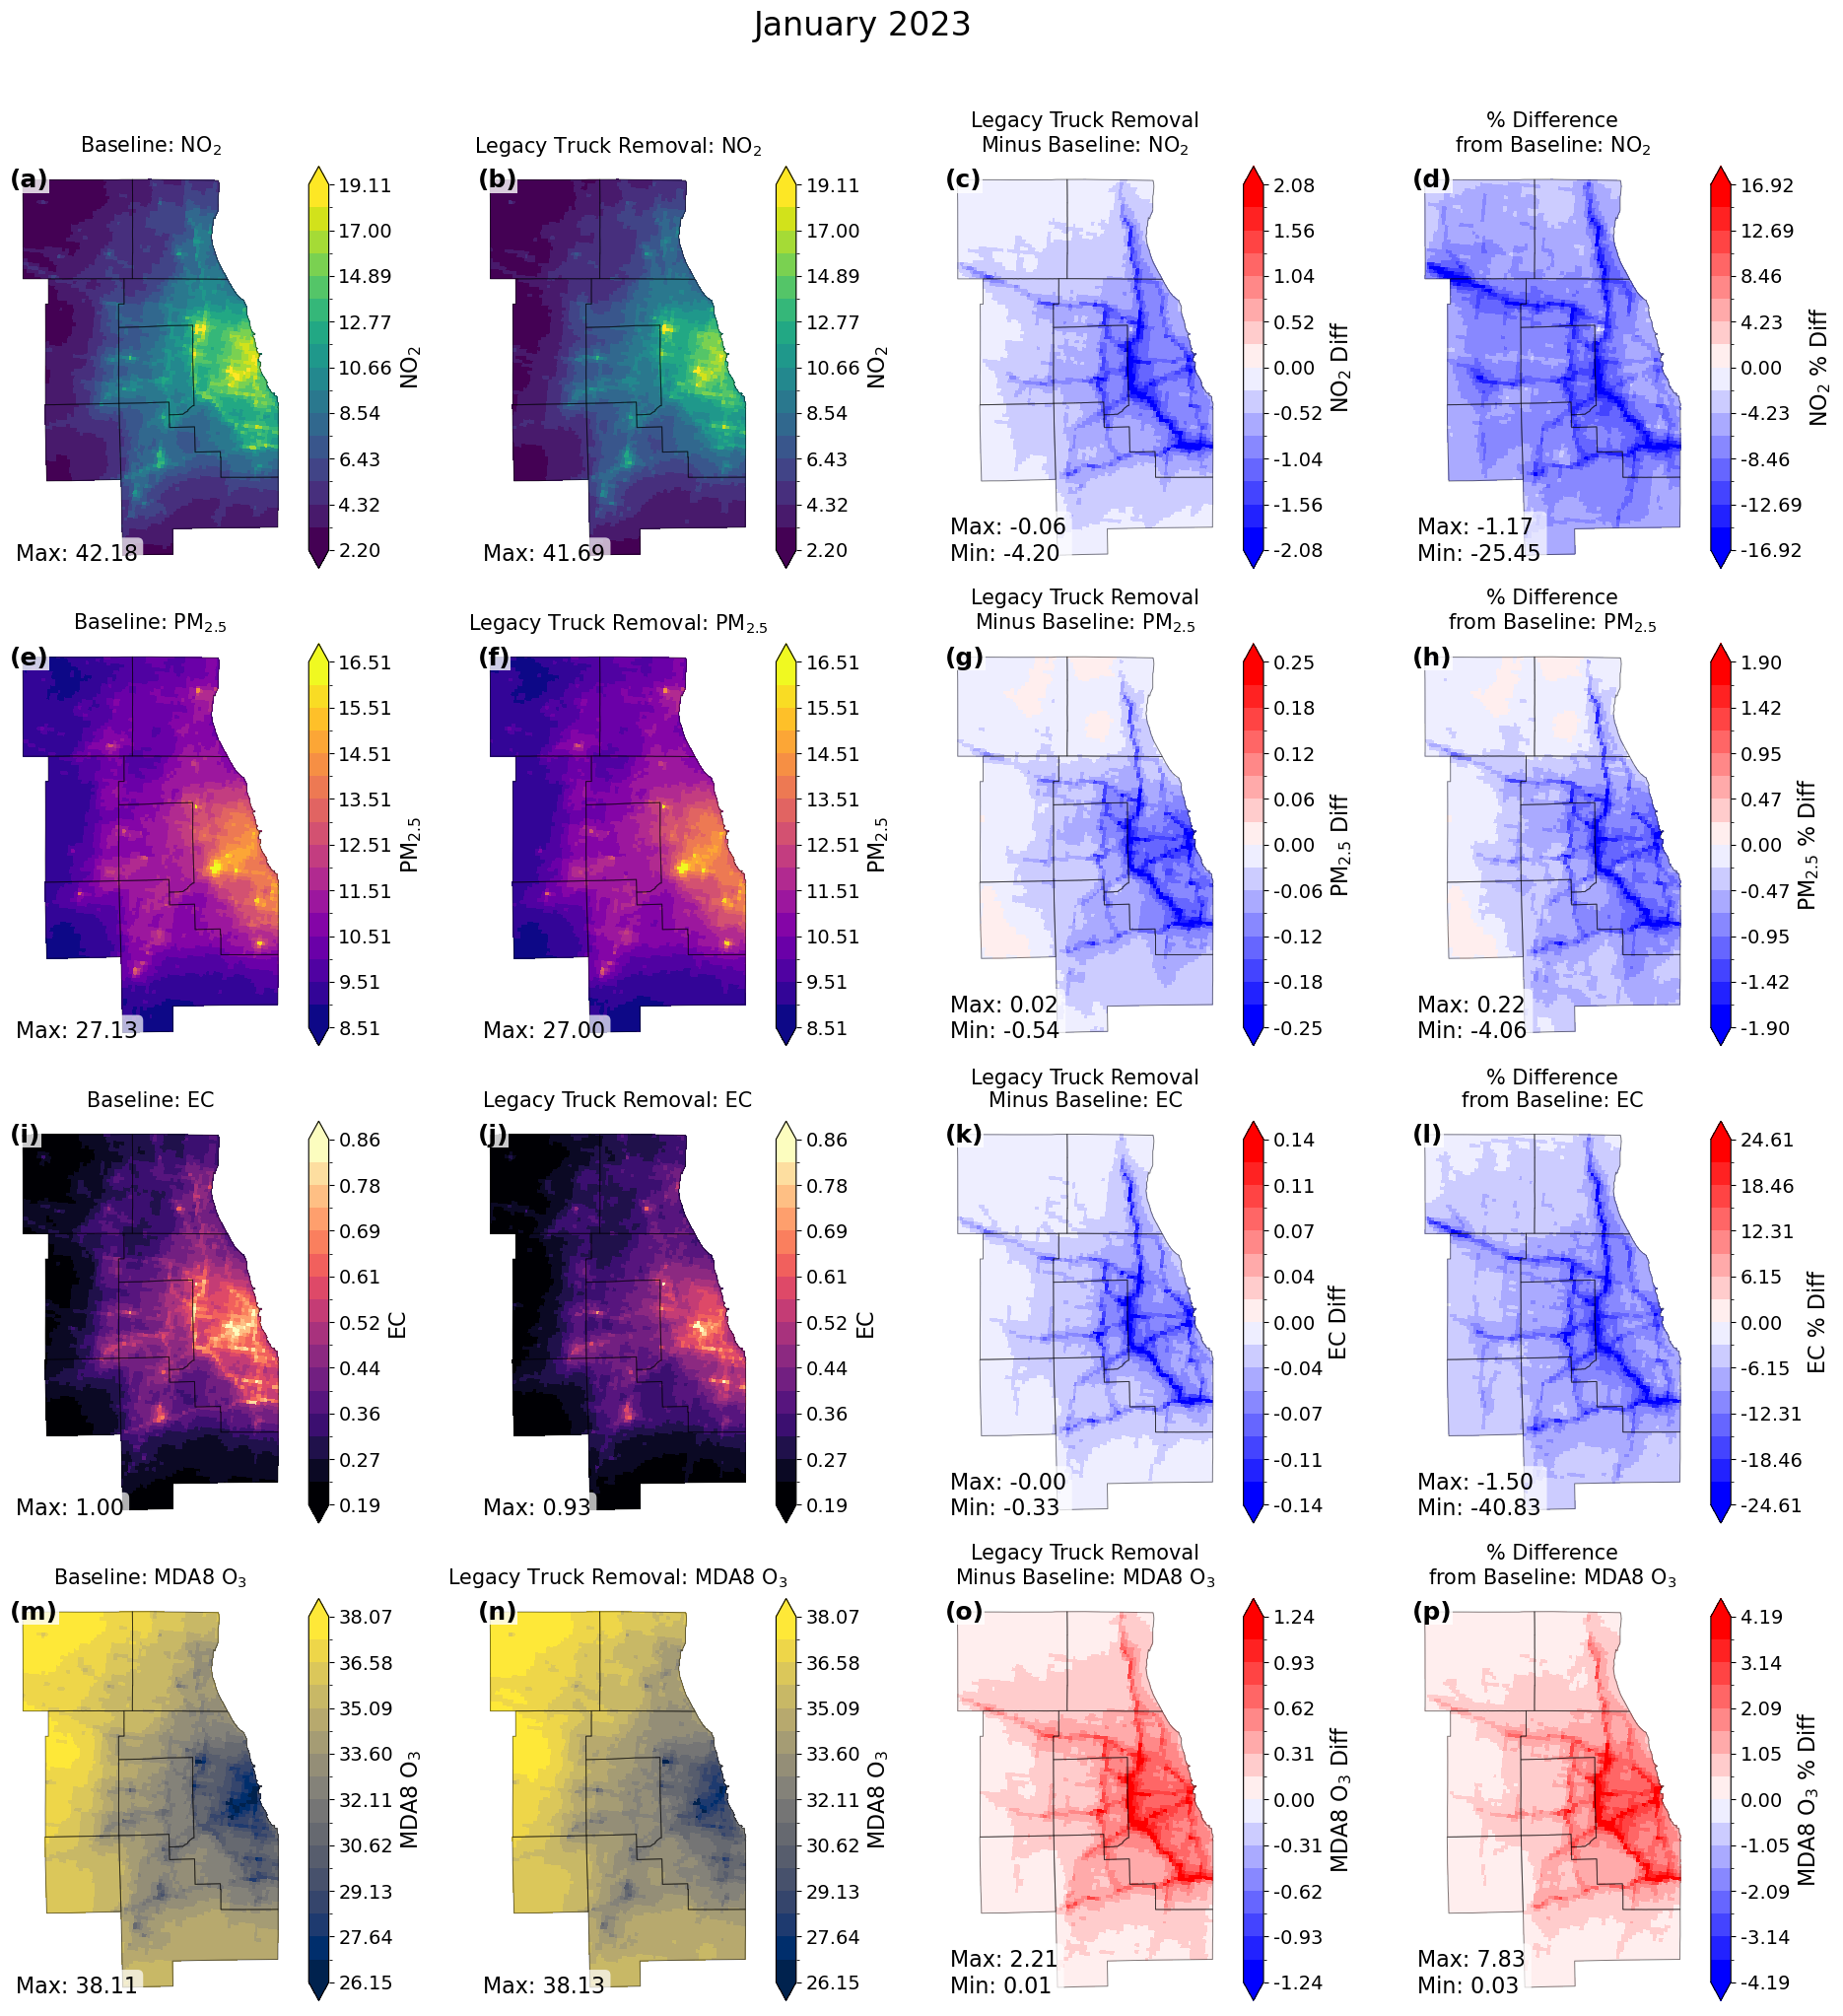

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:99: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:103: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.lins

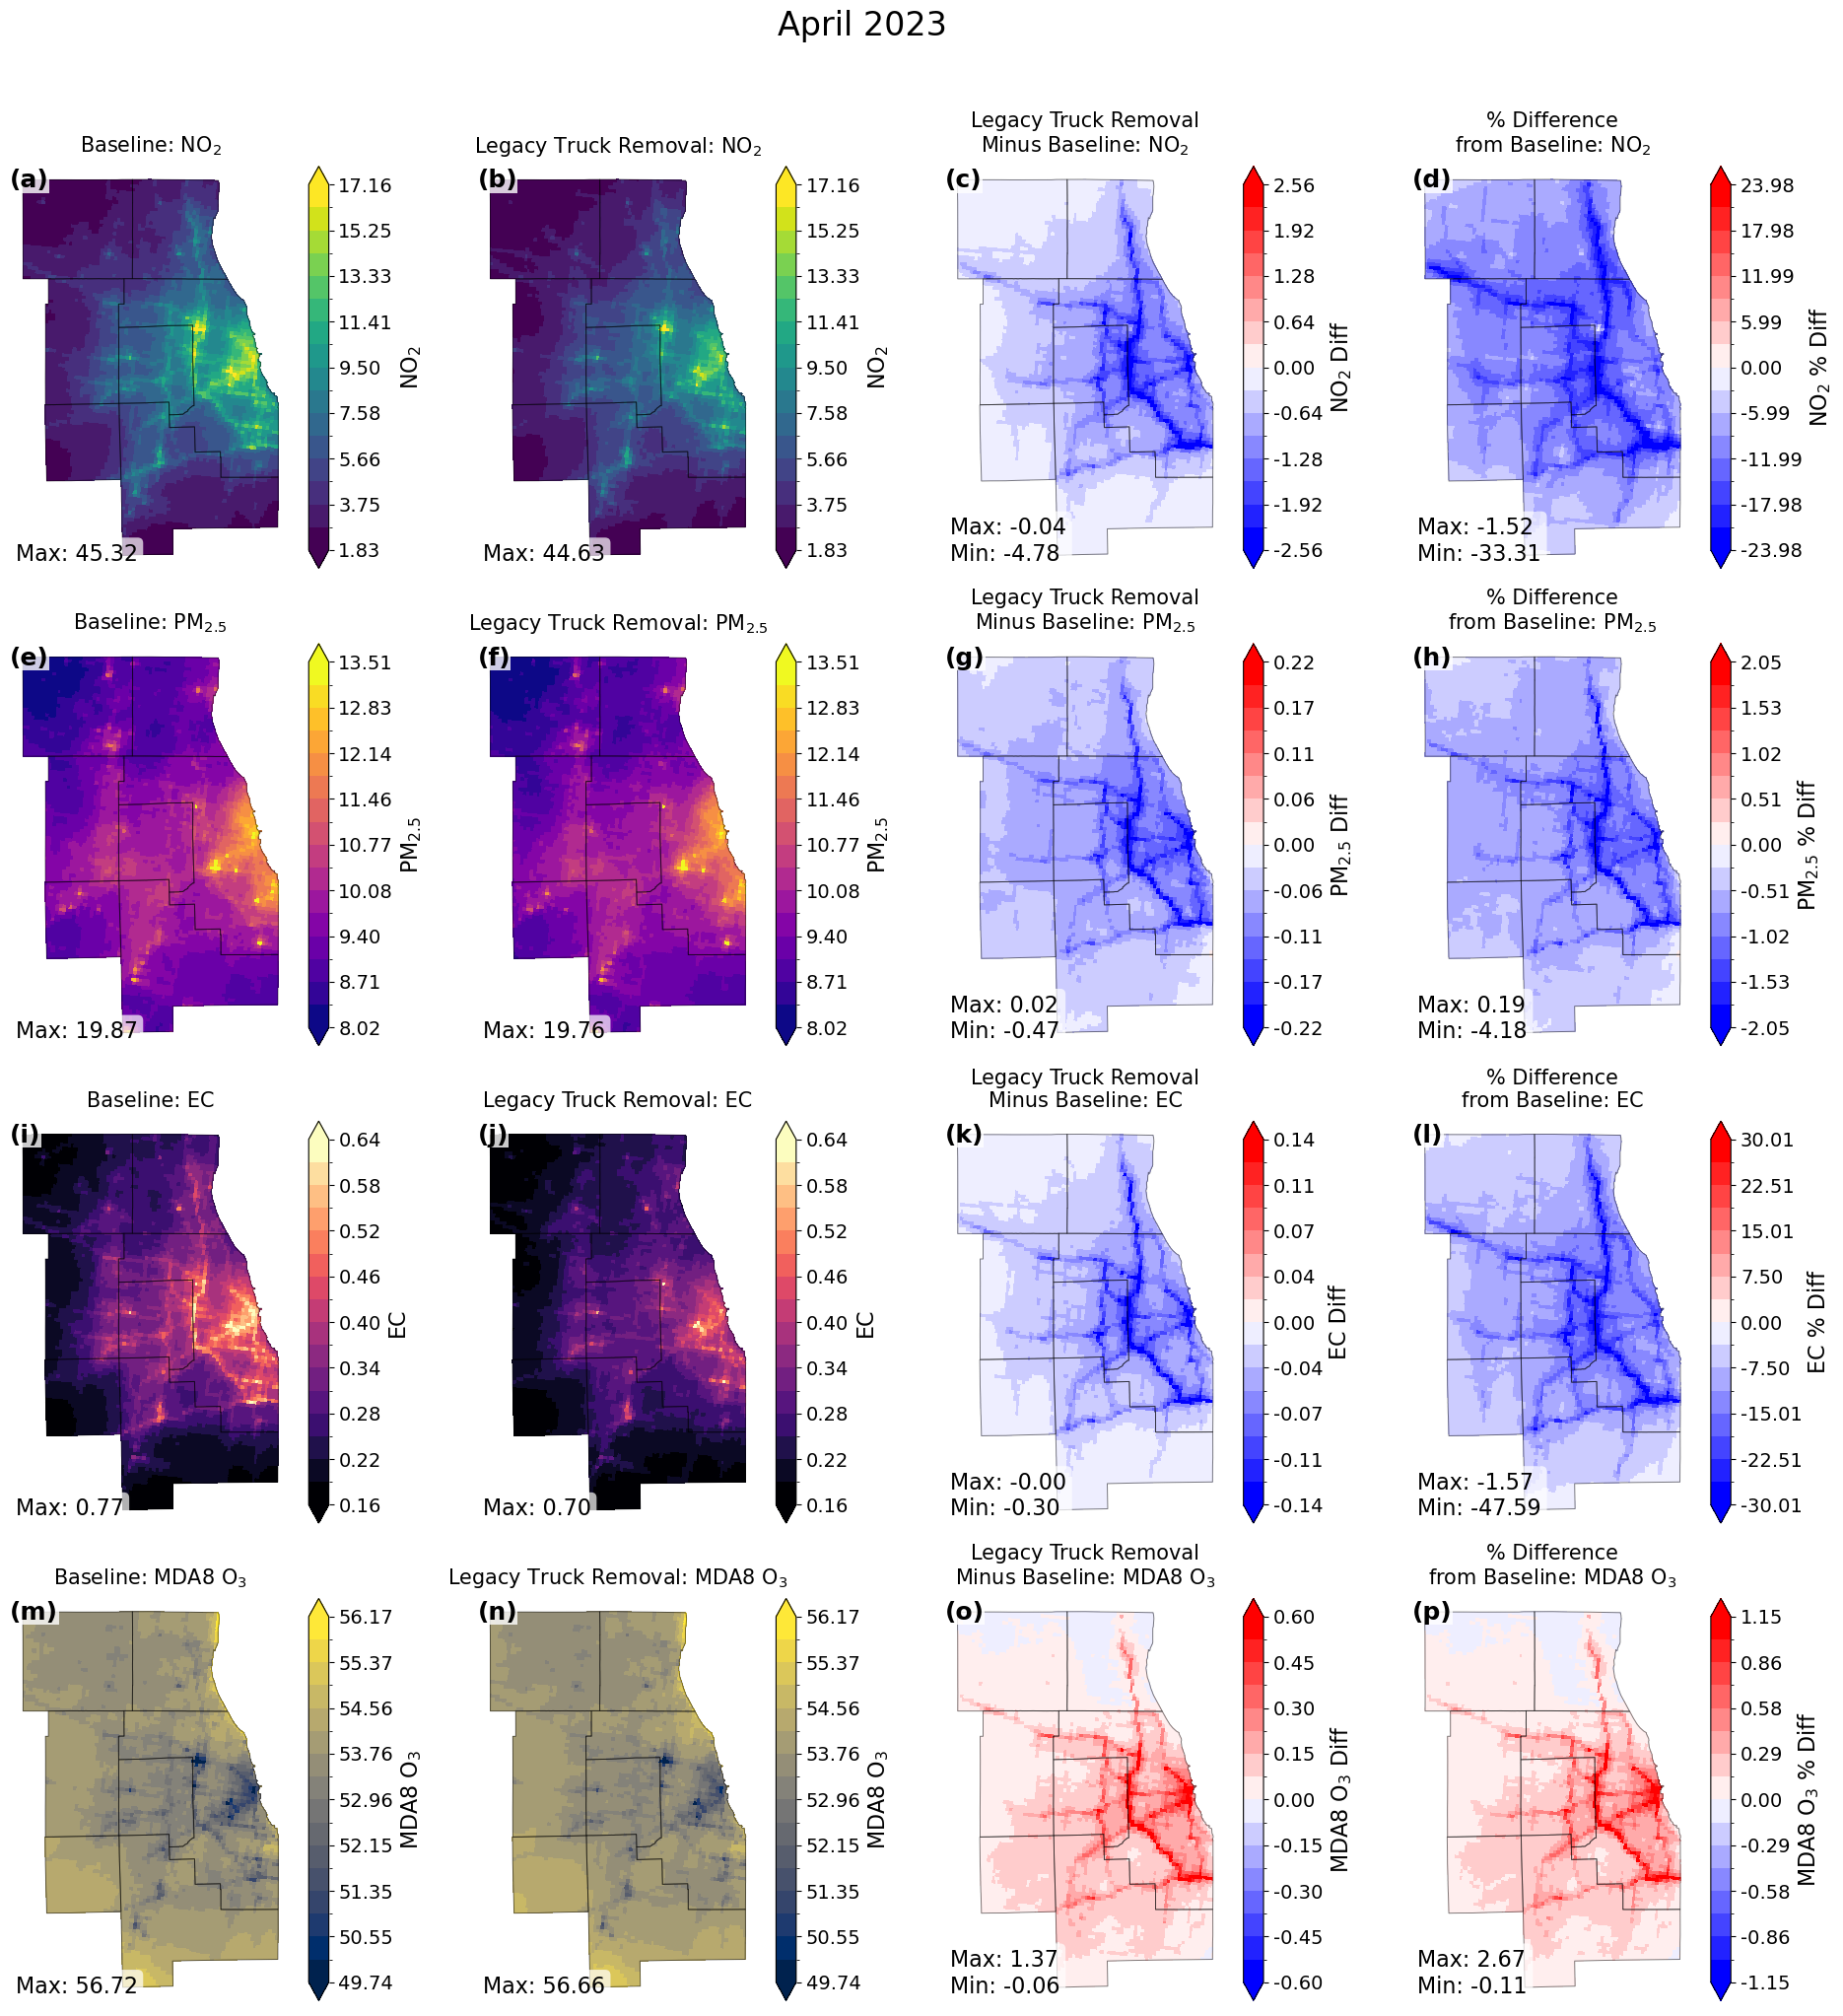

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:99: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:103: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.lins

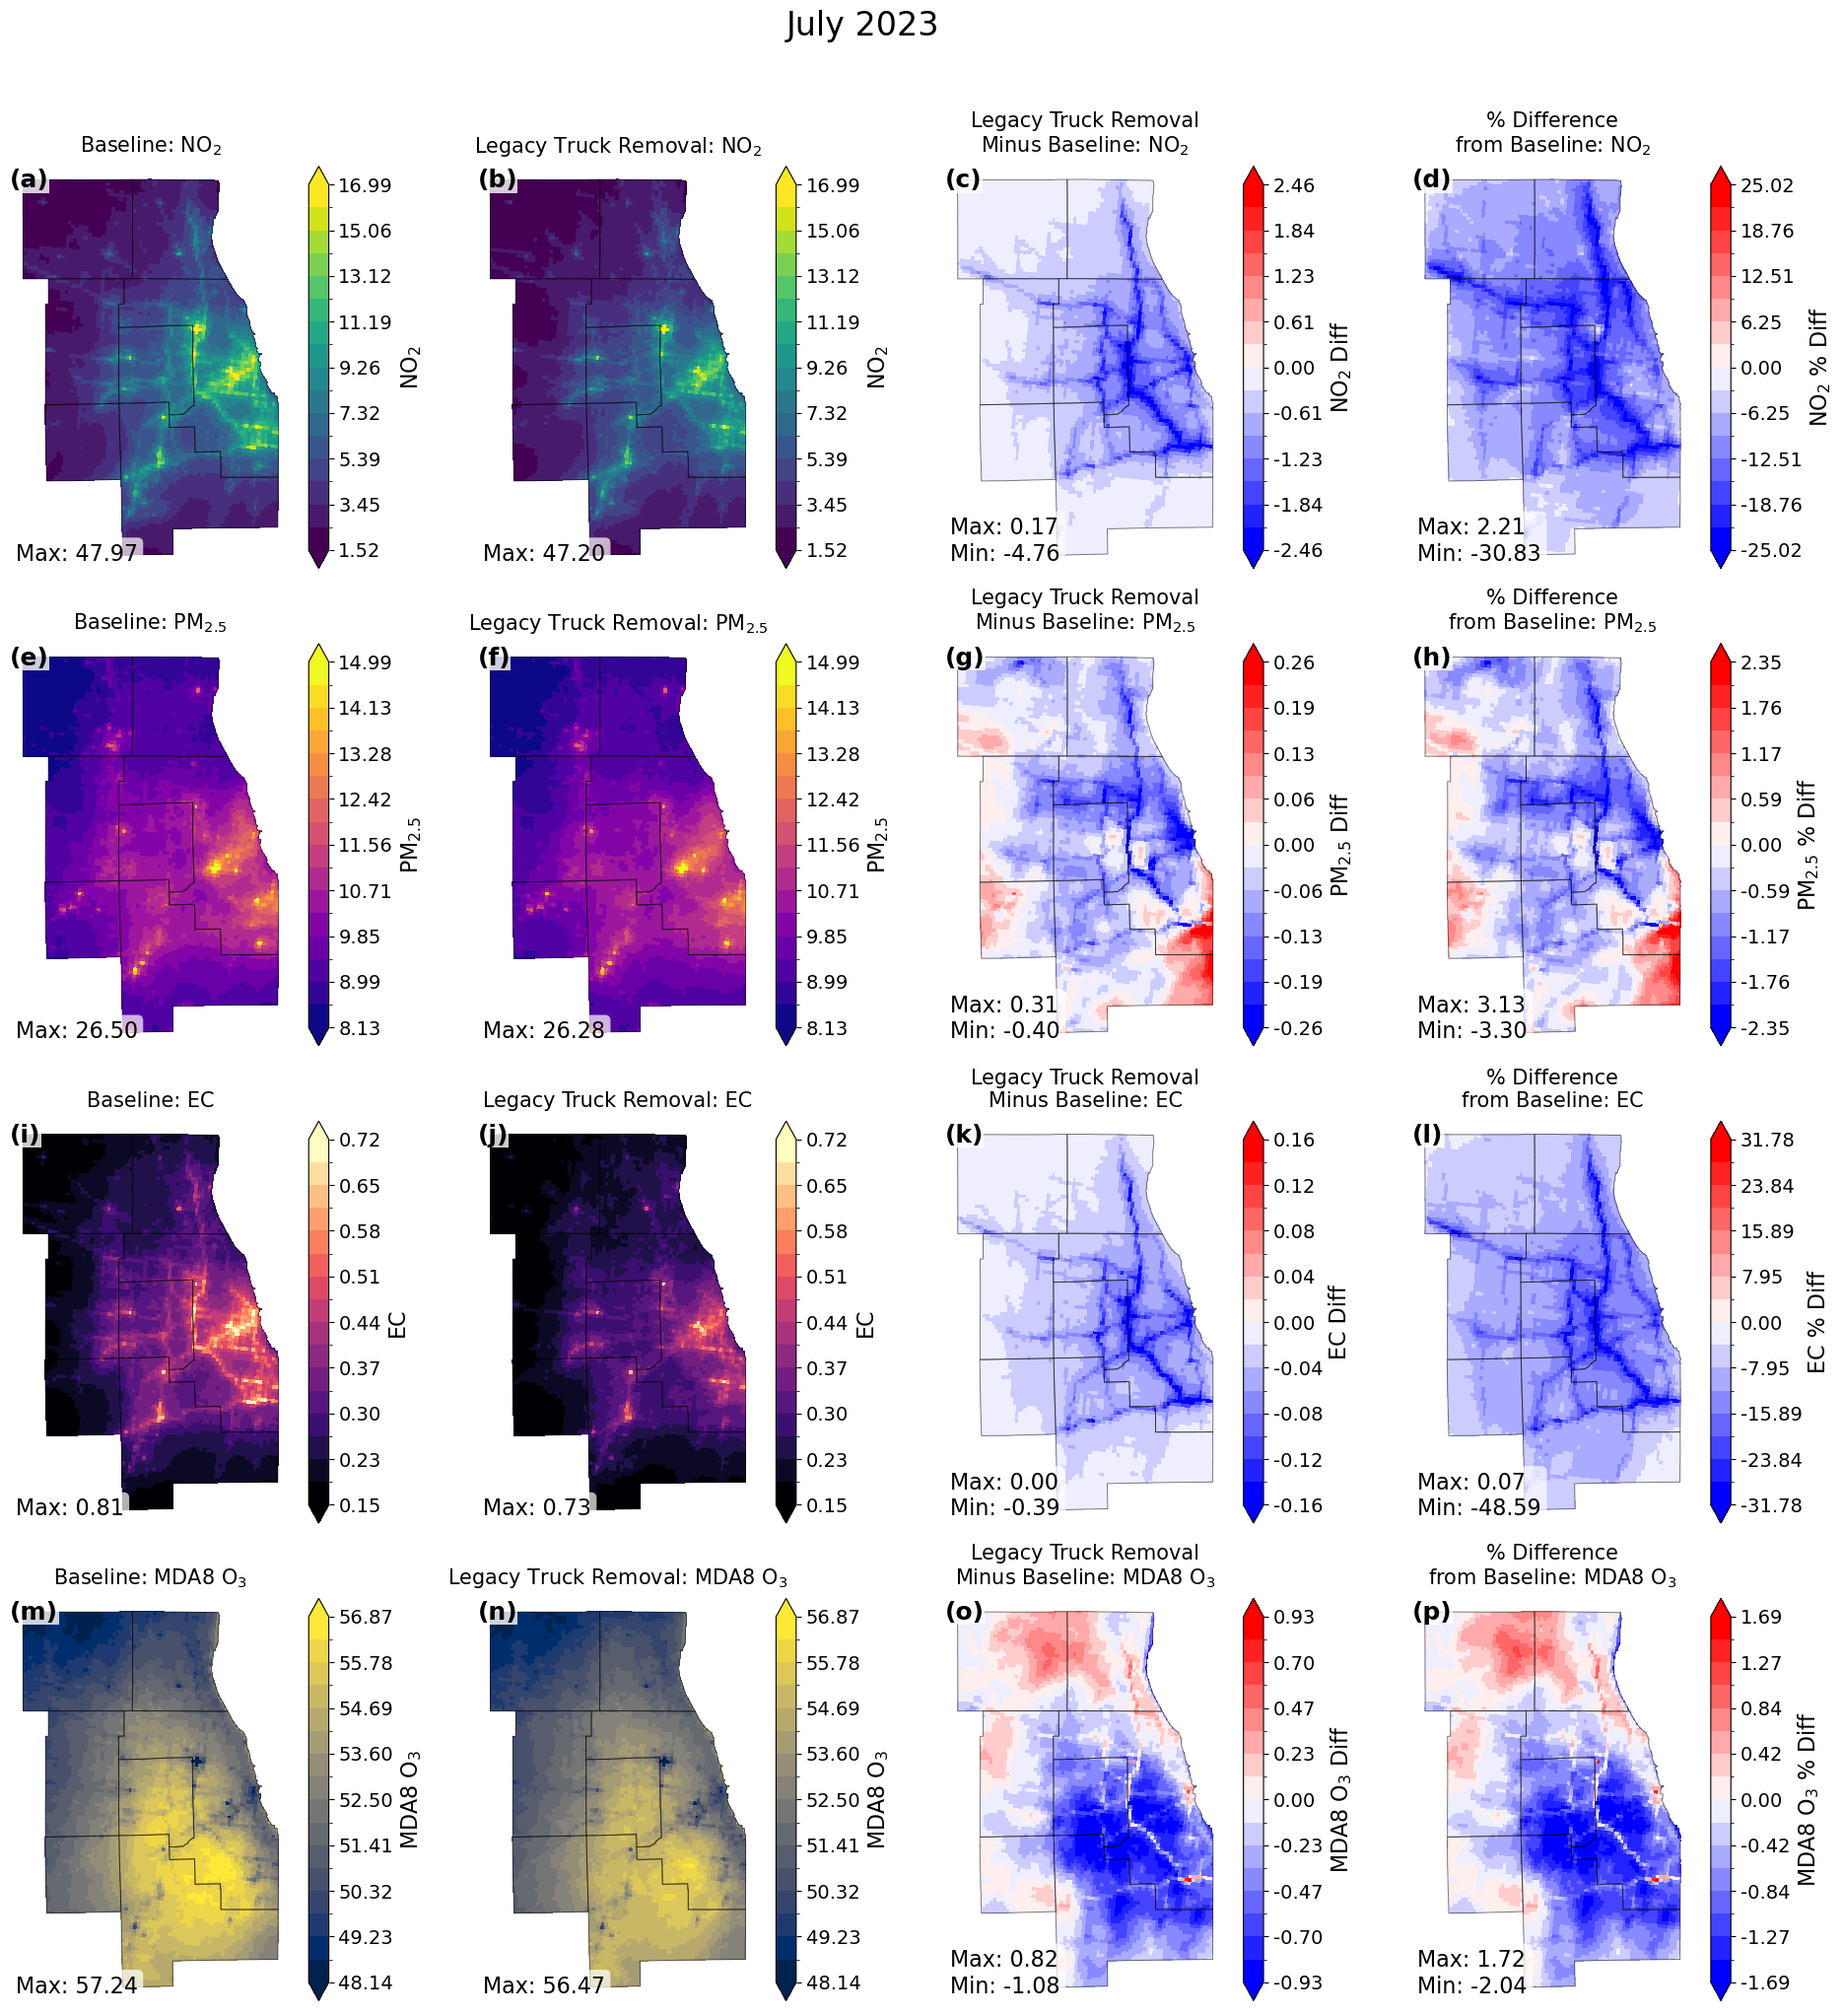

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:61: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:99: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\2911922584.py:103: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.lins

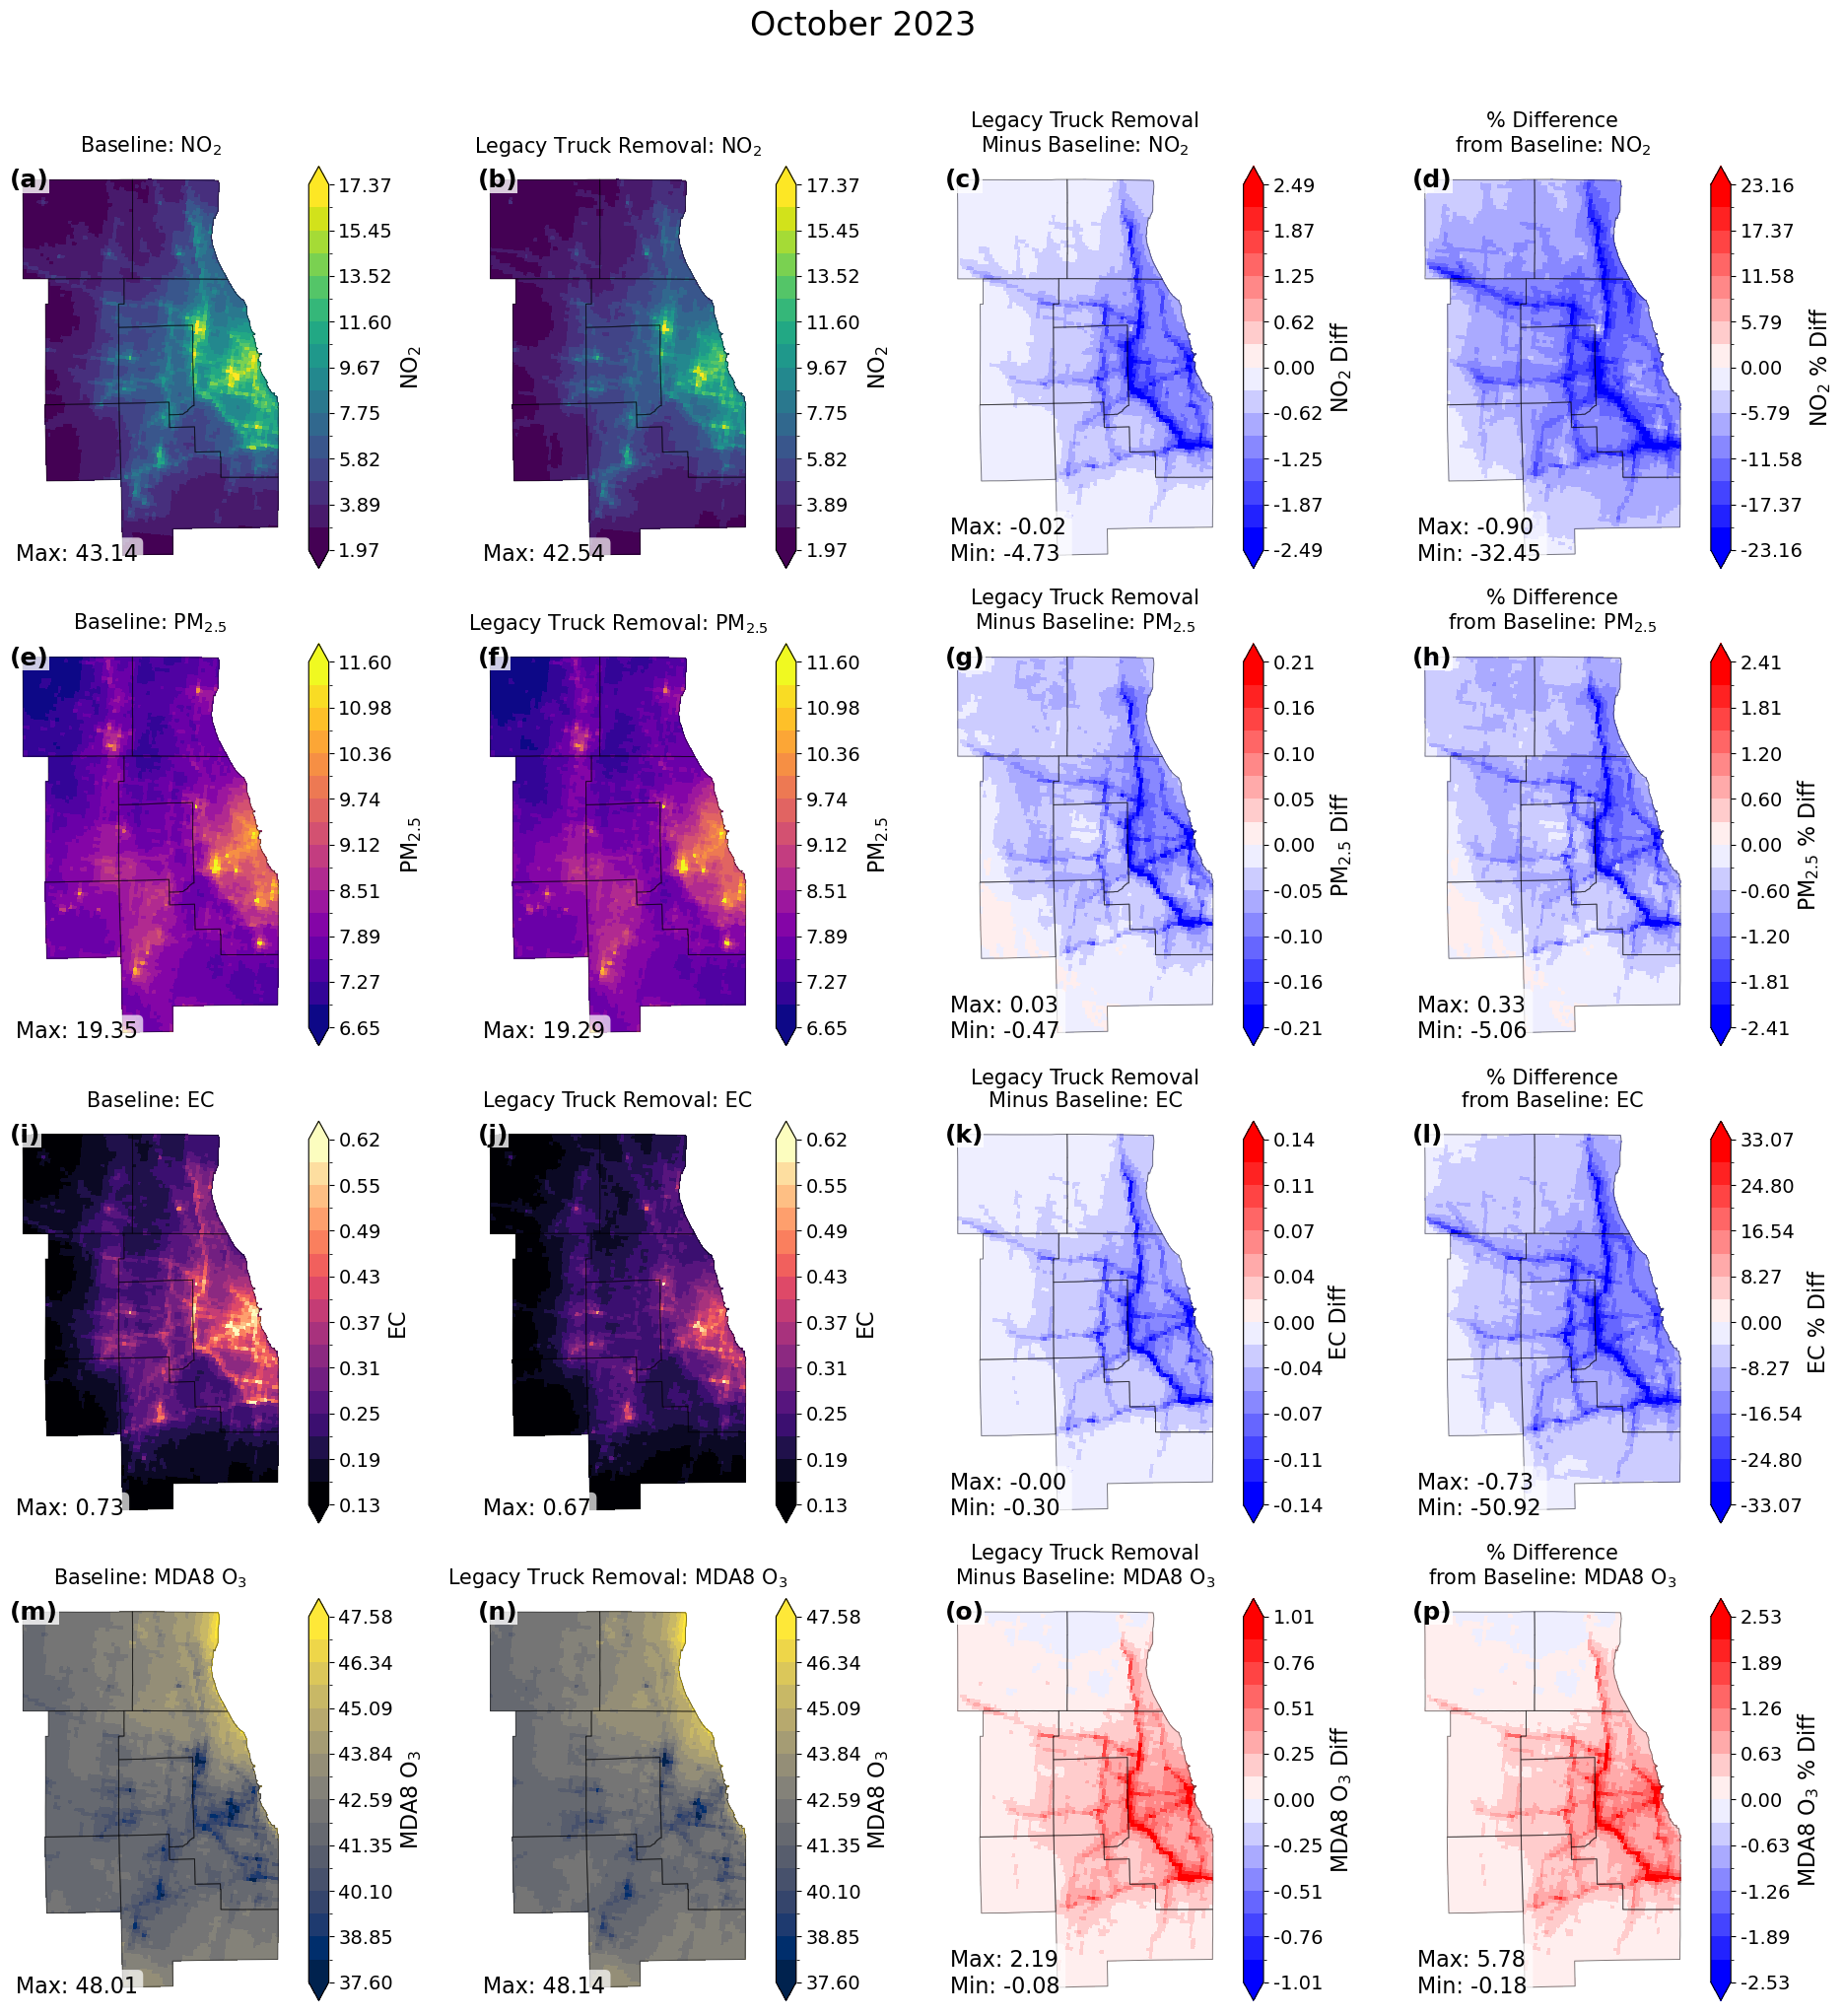

In [9]:
N_BINS = 16

months = ["Jan", "Apr", "Jul", "Oct"]
month_labels = {
    "Jan": "January",
    "Apr": "April",
    "Jul": "July",
    "Oct": "October",
}

pollutants = ["NO2", "PM25_TOT", "PM25_EC", "O3"]

scenario_names = [
    "Baseline",
    "Legacy Truck Removal",
    "Legacy Truck Removal\nMinus Baseline",
    "% Difference\nfrom Baseline",
]

plot_config = {
    "NO2": {"cmap_name": "viridis", "title": "NO$_2$", "label": "NO$_2$", "column": "NO2"},
    "PM25_TOT": {"cmap_name": "plasma", "title": "PM$_{2.5}$", "label": "PM$_{2.5}$", "column": "PM25_TOT"},
    "PM25_EC": {"cmap_name": "magma", "title": "EC", "label": "EC", "column": "PM25_EC"},
    "O3": {"cmap_name": "cividis", "title": "MDA8 O$_3$", "label": "MDA8 O$_3$", "column": "O3"},
}

monthly_gdfs_by_pol = {
    "NO2": {"reference": cmap_base, "scenario": cmap_zeropre2010s},
    "PM25_TOT": {"reference": cmap_base, "scenario": cmap_zeropre2010s},
    "PM25_EC": {"reference": cmap_base, "scenario": cmap_zeropre2010s},
    "O3": {"reference": cmap_base_o3, "scenario": cmap_zeropre2010s_o3},
}

def plot_monthly_default_locus(month):
    abs_styles = {}
    diff_styles = {}

    for pol in pollutants:
        cfg = plot_config[pol]
        col = cfg["column"]

        reference_gdf = monthly_gdfs_by_pol[pol]["reference"][month]
        scenario_gdf = monthly_gdfs_by_pol[pol]["scenario"][month]

        vals_all = []

        for gdf in [reference_gdf, scenario_gdf]:
            vals = gdf[col].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            vals_all.append(vals)

        vals_all = np.concatenate(vals_all)

        vmin = np.quantile(vals_all, 0.001)
        vmax = np.quantile(vals_all, 0.999)

        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6

        cmap_disc = ListedColormap(
            plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
        )

        bounds = np.linspace(vmin, vmax, N_BINS + 1)
        norm = BoundaryNorm(bounds, cmap_disc.N)

        abs_styles[pol] = {
            "bounds": bounds,
            "cmap": cmap_disc,
            "norm": norm,
        }

        reference_vals = reference_gdf[col].astype(float).to_numpy()
        scenario_vals = scenario_gdf[col].astype(float).to_numpy()

        diff_vals = scenario_vals - reference_vals

        pct_vals = np.where(
            reference_vals != 0,
            (diff_vals / reference_vals) * 100.0,
            np.nan,
        )

        diff_vals_finite = diff_vals[np.isfinite(diff_vals)]
        pct_vals_finite = pct_vals[np.isfinite(pct_vals)]

        diff_lim = np.quantile(np.abs(diff_vals_finite), 0.99)
        pct_lim = np.quantile(np.abs(pct_vals_finite), 0.99)

        if np.isclose(diff_lim, 0):
            diff_lim = 1e-6
        if np.isclose(pct_lim, 0):
            pct_lim = 1e-6

        diff_bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
        pct_bounds = np.linspace(-pct_lim, pct_lim, N_BINS + 1)

        diff_cmap = ListedColormap(
            plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
        )

        pct_cmap = ListedColormap(
            plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
        )

        diff_styles[pol] = {
            "diff_bounds": diff_bounds,
            "diff_cmap": diff_cmap,
            "diff_norm": BoundaryNorm(diff_bounds, diff_cmap.N),
            "pct_bounds": pct_bounds,
            "pct_cmap": pct_cmap,
            "pct_norm": BoundaryNorm(pct_bounds, pct_cmap.N),
        }

    scenario_gdfs_by_pol = {}

    for pol in pollutants:
        cfg = plot_config[pol]
        col = cfg["column"]

        reference_gdf = monthly_gdfs_by_pol[pol]["reference"][month]
        scenario_gdf = monthly_gdfs_by_pol[pol]["scenario"][month]

        plot_reference = reference_gdf.copy()
        plot_scenario = scenario_gdf.copy()
        plot_diff = scenario_gdf.copy()
        plot_pct = scenario_gdf.copy()

        plot_reference[pol] = plot_reference[col].astype(float)
        plot_scenario[pol] = plot_scenario[col].astype(float)

        plot_diff[pol] = (
            scenario_gdf[col].astype(float)
            - reference_gdf[col].astype(float)
        )

        plot_pct[pol] = np.where(
            reference_gdf[col].astype(float) != 0,
            (
                (
                    scenario_gdf[col].astype(float)
                    - reference_gdf[col].astype(float)
                )
                / reference_gdf[col].astype(float)
            )
            * 100.0,
            np.nan,
        )

        scenario_gdfs_by_pol[pol] = {
            scenario_names[0]: plot_reference,
            scenario_names[1]: plot_scenario,
            scenario_names[2]: plot_diff,
            scenario_names[3]: plot_pct,
        }

    fig, axs = plt.subplots(
        nrows=len(pollutants),
        ncols=4,
        figsize=(20, 20),
        subplot_kw={"projection": ccrs.PlateCarree()},
    )

    fig.suptitle(
        f"{month_labels[month]} 2023",
        fontsize=24,
        y=1.02,
    )

    for i, pol in enumerate(pollutants):
        for j, scen in enumerate(scenario_names):
            ax = axs[i, j]

            panel_label = f"({chr(97 + i * 4 + j)})"

            ax.text(
                0.001,
                0.98,
                panel_label,
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=18,
                fontweight="bold",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.2),
            )

            gdf = scenario_gdfs_by_pol[pol][scen]

            if j in [0, 1]:
                style = abs_styles[pol]
                cmap_disc = style["cmap"]
                norm = style["norm"]
                bounds = style["bounds"]
                extend_opt = "both"

            elif j == 2:
                style = diff_styles[pol]
                cmap_disc = style["diff_cmap"]
                norm = style["diff_norm"]
                bounds = style["diff_bounds"]
                extend_opt = "both"

            else:
                style = diff_styles[pol]
                cmap_disc = style["pct_cmap"]
                norm = style["pct_norm"]
                bounds = style["pct_bounds"]
                extend_opt = "both"

            gdf.plot(
                column=pol,
                ax=ax,
                cmap=cmap_disc,
                norm=norm,
                edgecolor="none",
                antialiased=False,
            )

            cmap_cty.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)

            ax.set_title(f"{scen}: {plot_config[pol]['title']}", fontsize=15)
            ax.set_axis_off()

            sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
            sm._A = []

            cbar = fig.colorbar(
                sm,
                ax=ax,
                fraction=0.046,
                pad=0.04,
                boundaries=bounds,
                ticks=bounds[::2],
                spacing="proportional",
                extend=extend_opt,
            )

            cbar.ax.tick_params(labelsize=14)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 3:
                cbar.set_label(f"{plot_config[pol]['label']} % Diff", fontsize=16)
            elif j == 2:
                cbar.set_label(f"{plot_config[pol]['label']} Diff", fontsize=16)
            else:
                cbar.set_label(plot_config[pol]["label"], fontsize=16)

            vals = gdf[pol].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]

            vmax_panel = float(np.nanmax(vals))
            vmin_panel = float(np.nanmin(vals))

            if j in [0, 1]:
                annot_text = f"Max: {vmax_panel:.2f}"
            else:
                annot_text = f"Max: {vmax_panel:.2f}\nMin: {vmin_panel:.2f}"

            ax.text(
                0.02,
                0.02,
                annot_text,
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=16,
                color="black",
                bbox=dict(
                    facecolor="white",
                    alpha=0.7,
                    boxstyle="round,pad=0.25",
                    linewidth=0,
                ),
            )

    plt.tight_layout()
    plt.savefig(f"Fig_Default_zeropre2010s_griddedAirPoll_{month}.png", dpi=500)
    plt.show()

for month in months:
    plot_monthly_default_locus(month)

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:76: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:79: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0,

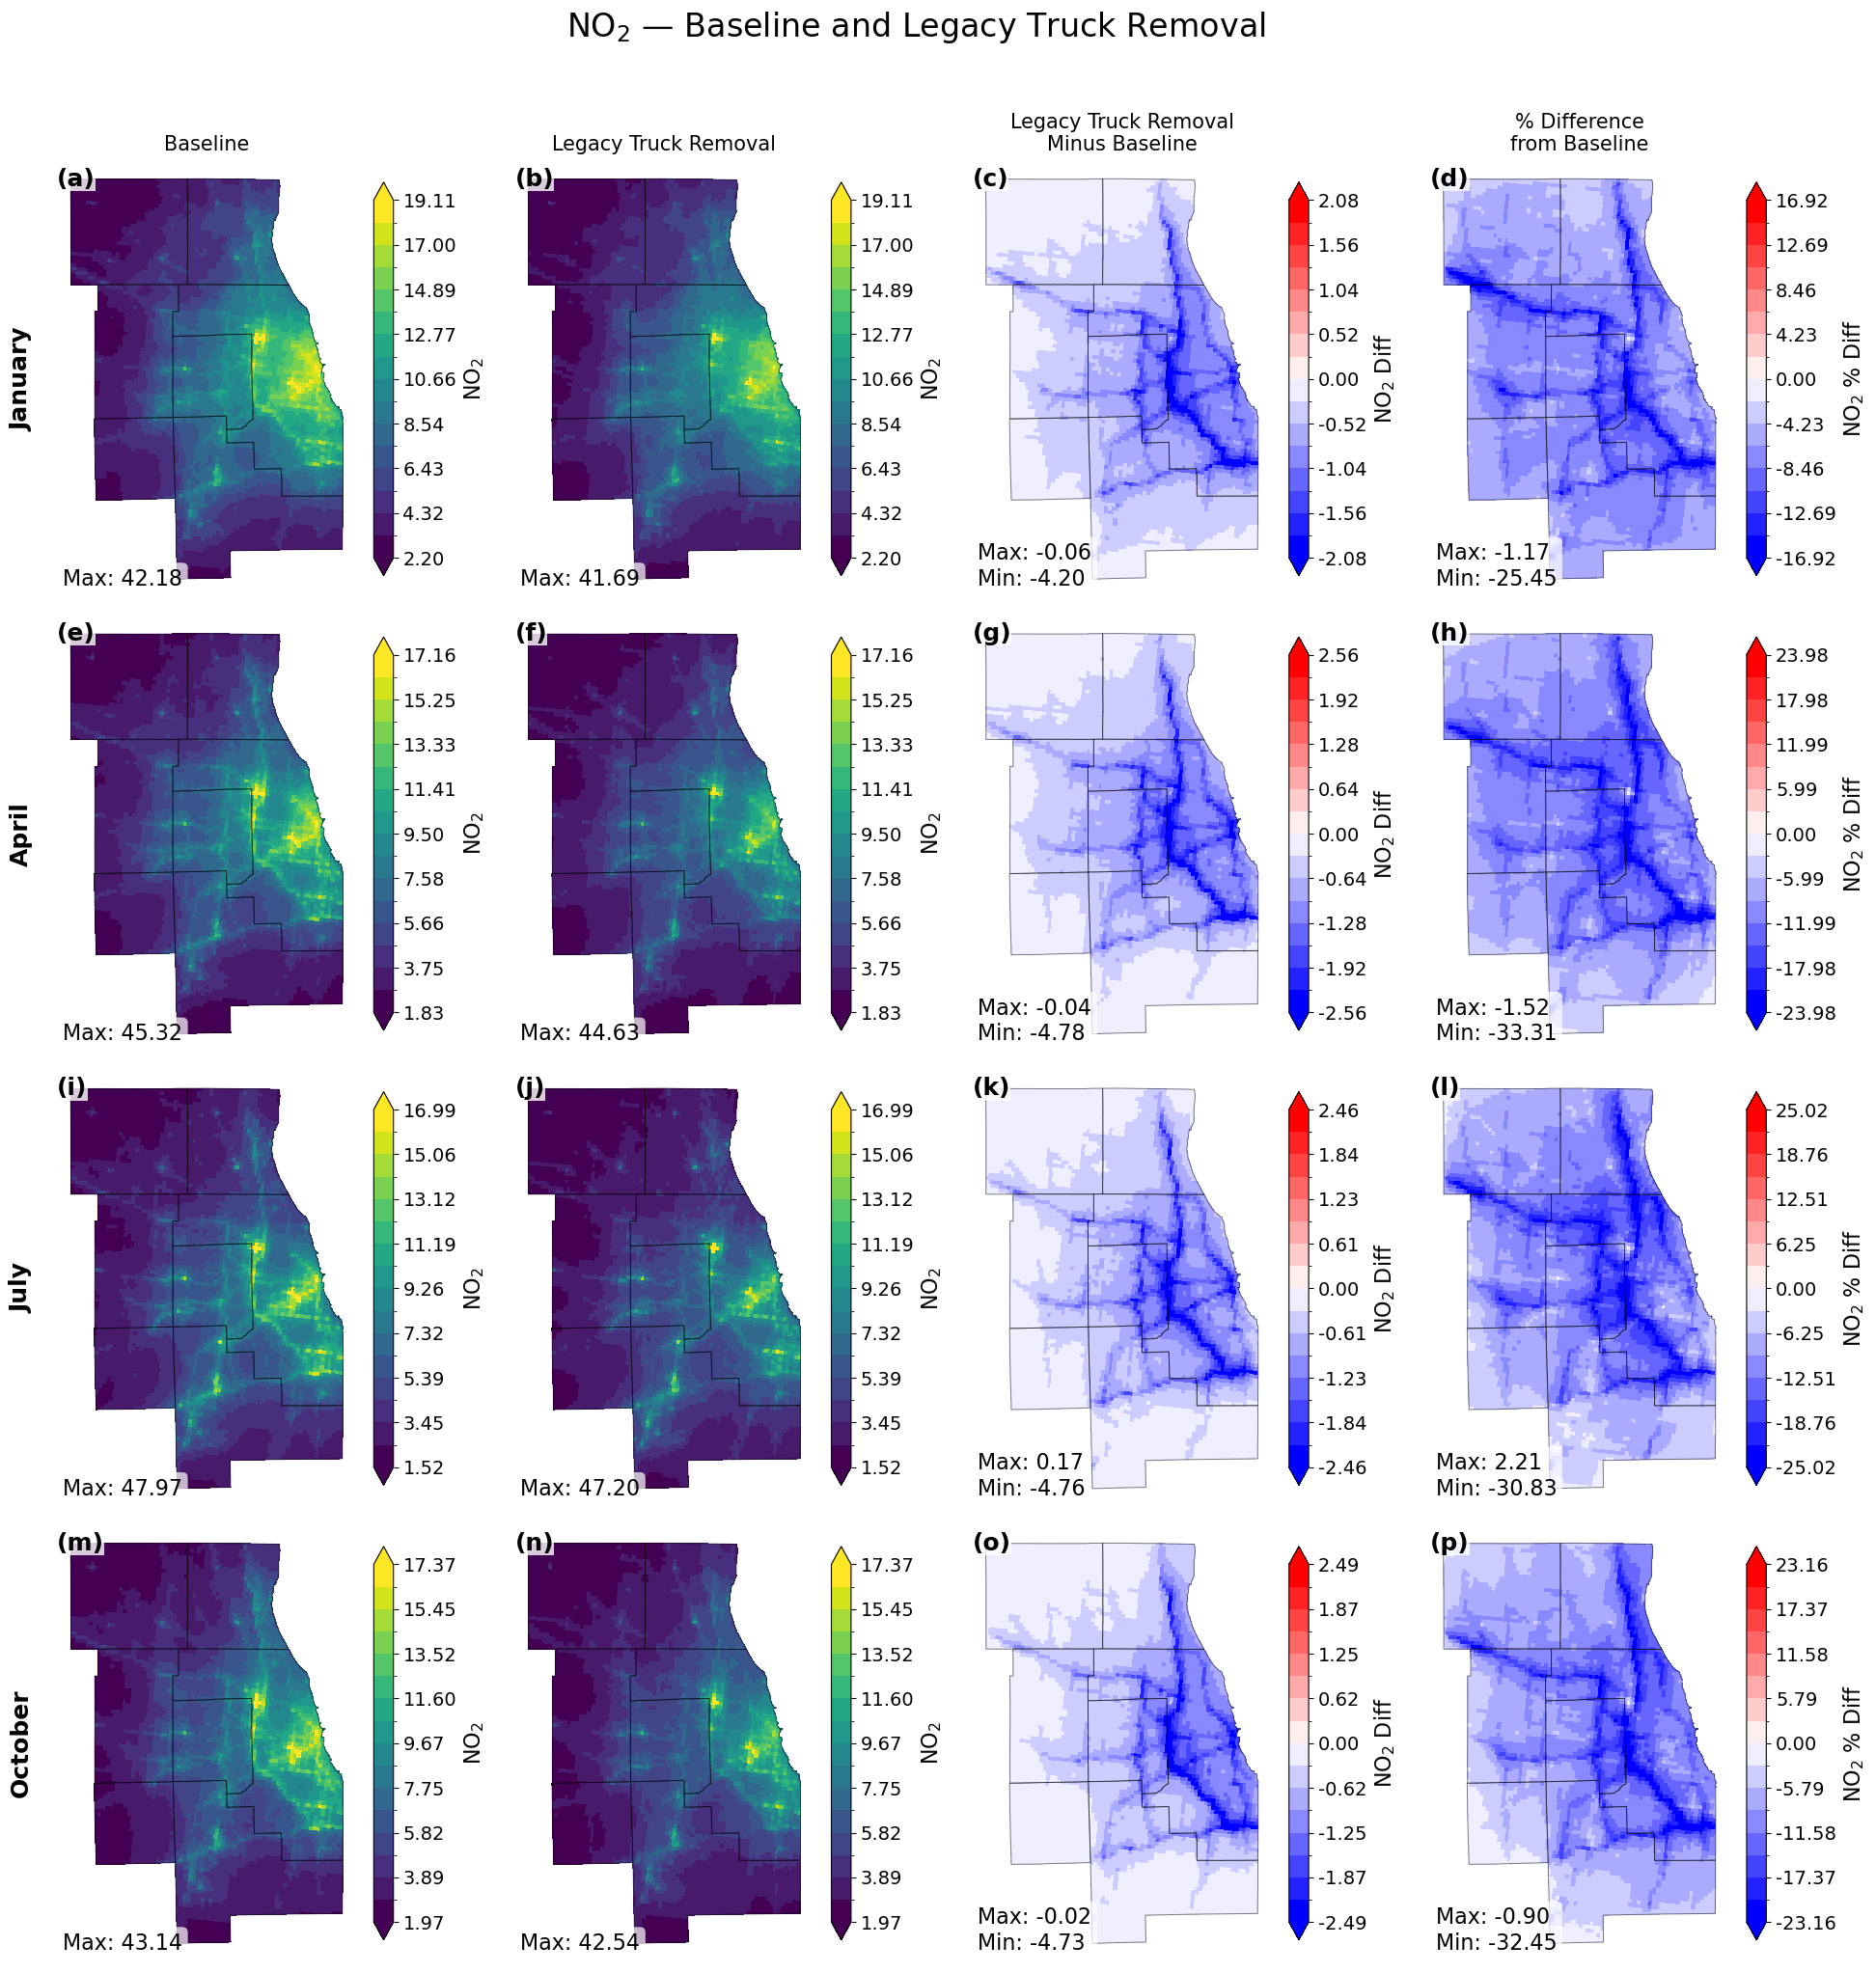

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:76: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:79: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0,

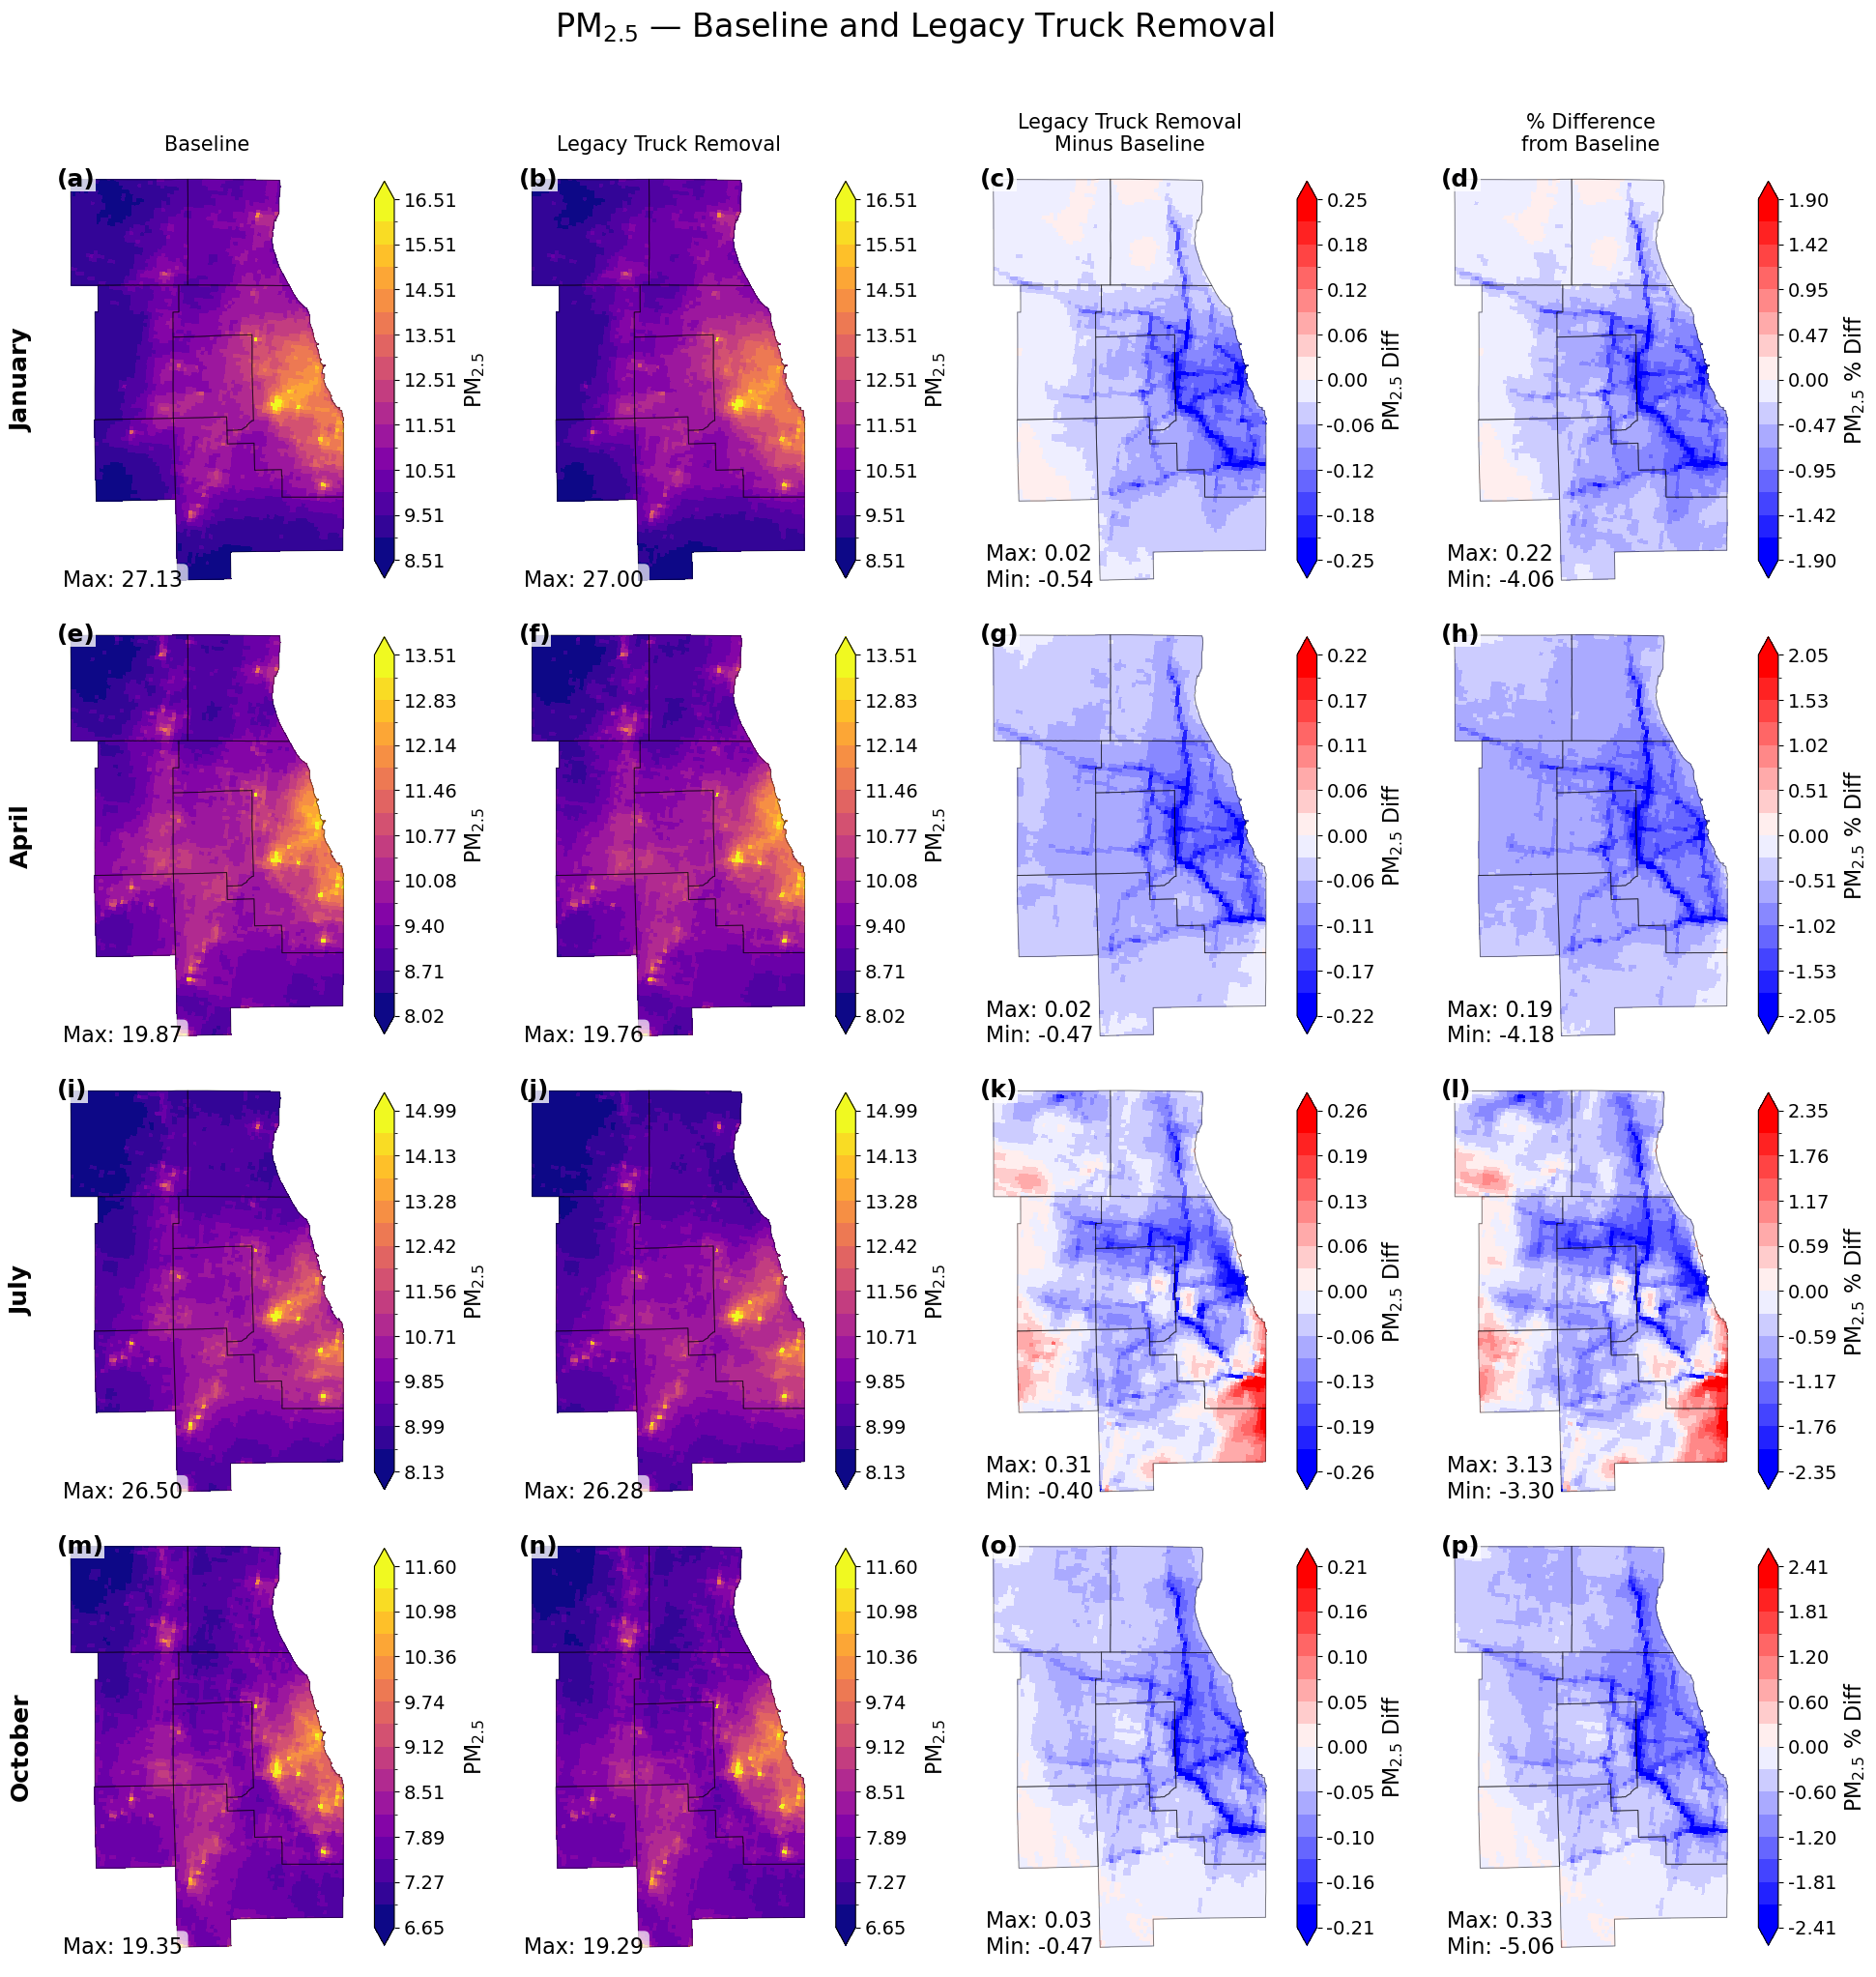

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:76: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:79: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0,

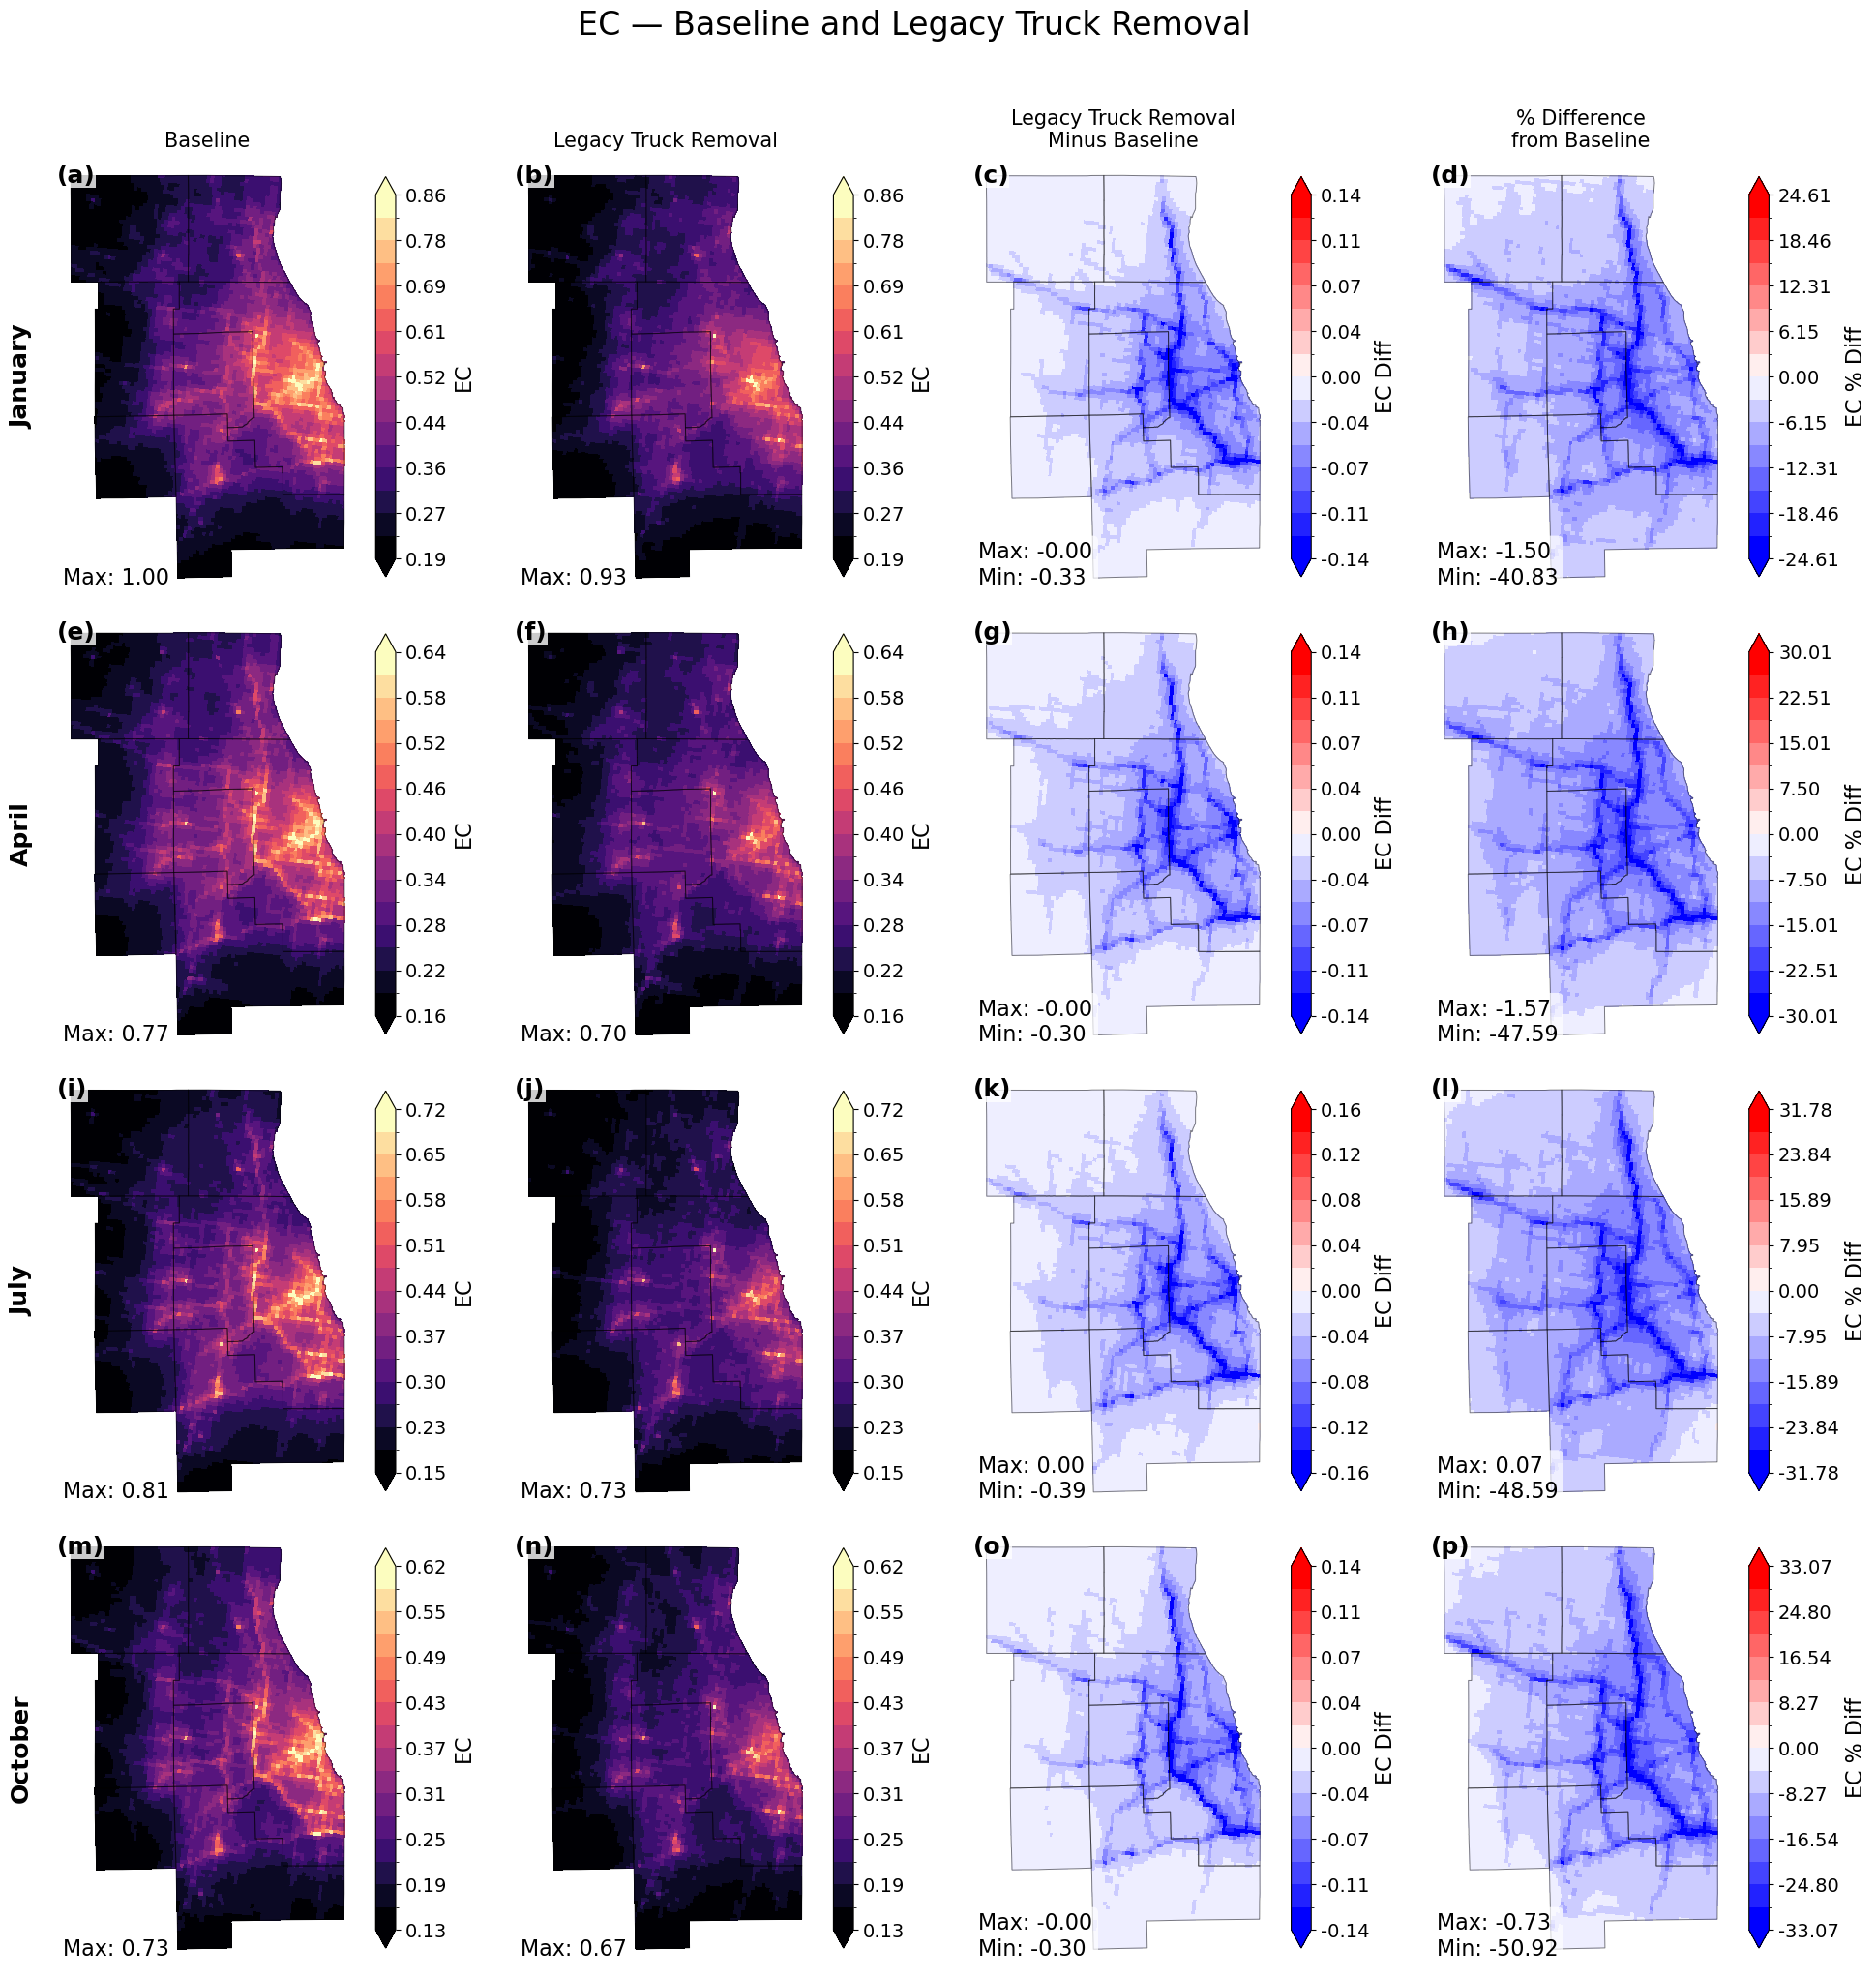

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:41: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:76: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\77983777.py:79: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0,

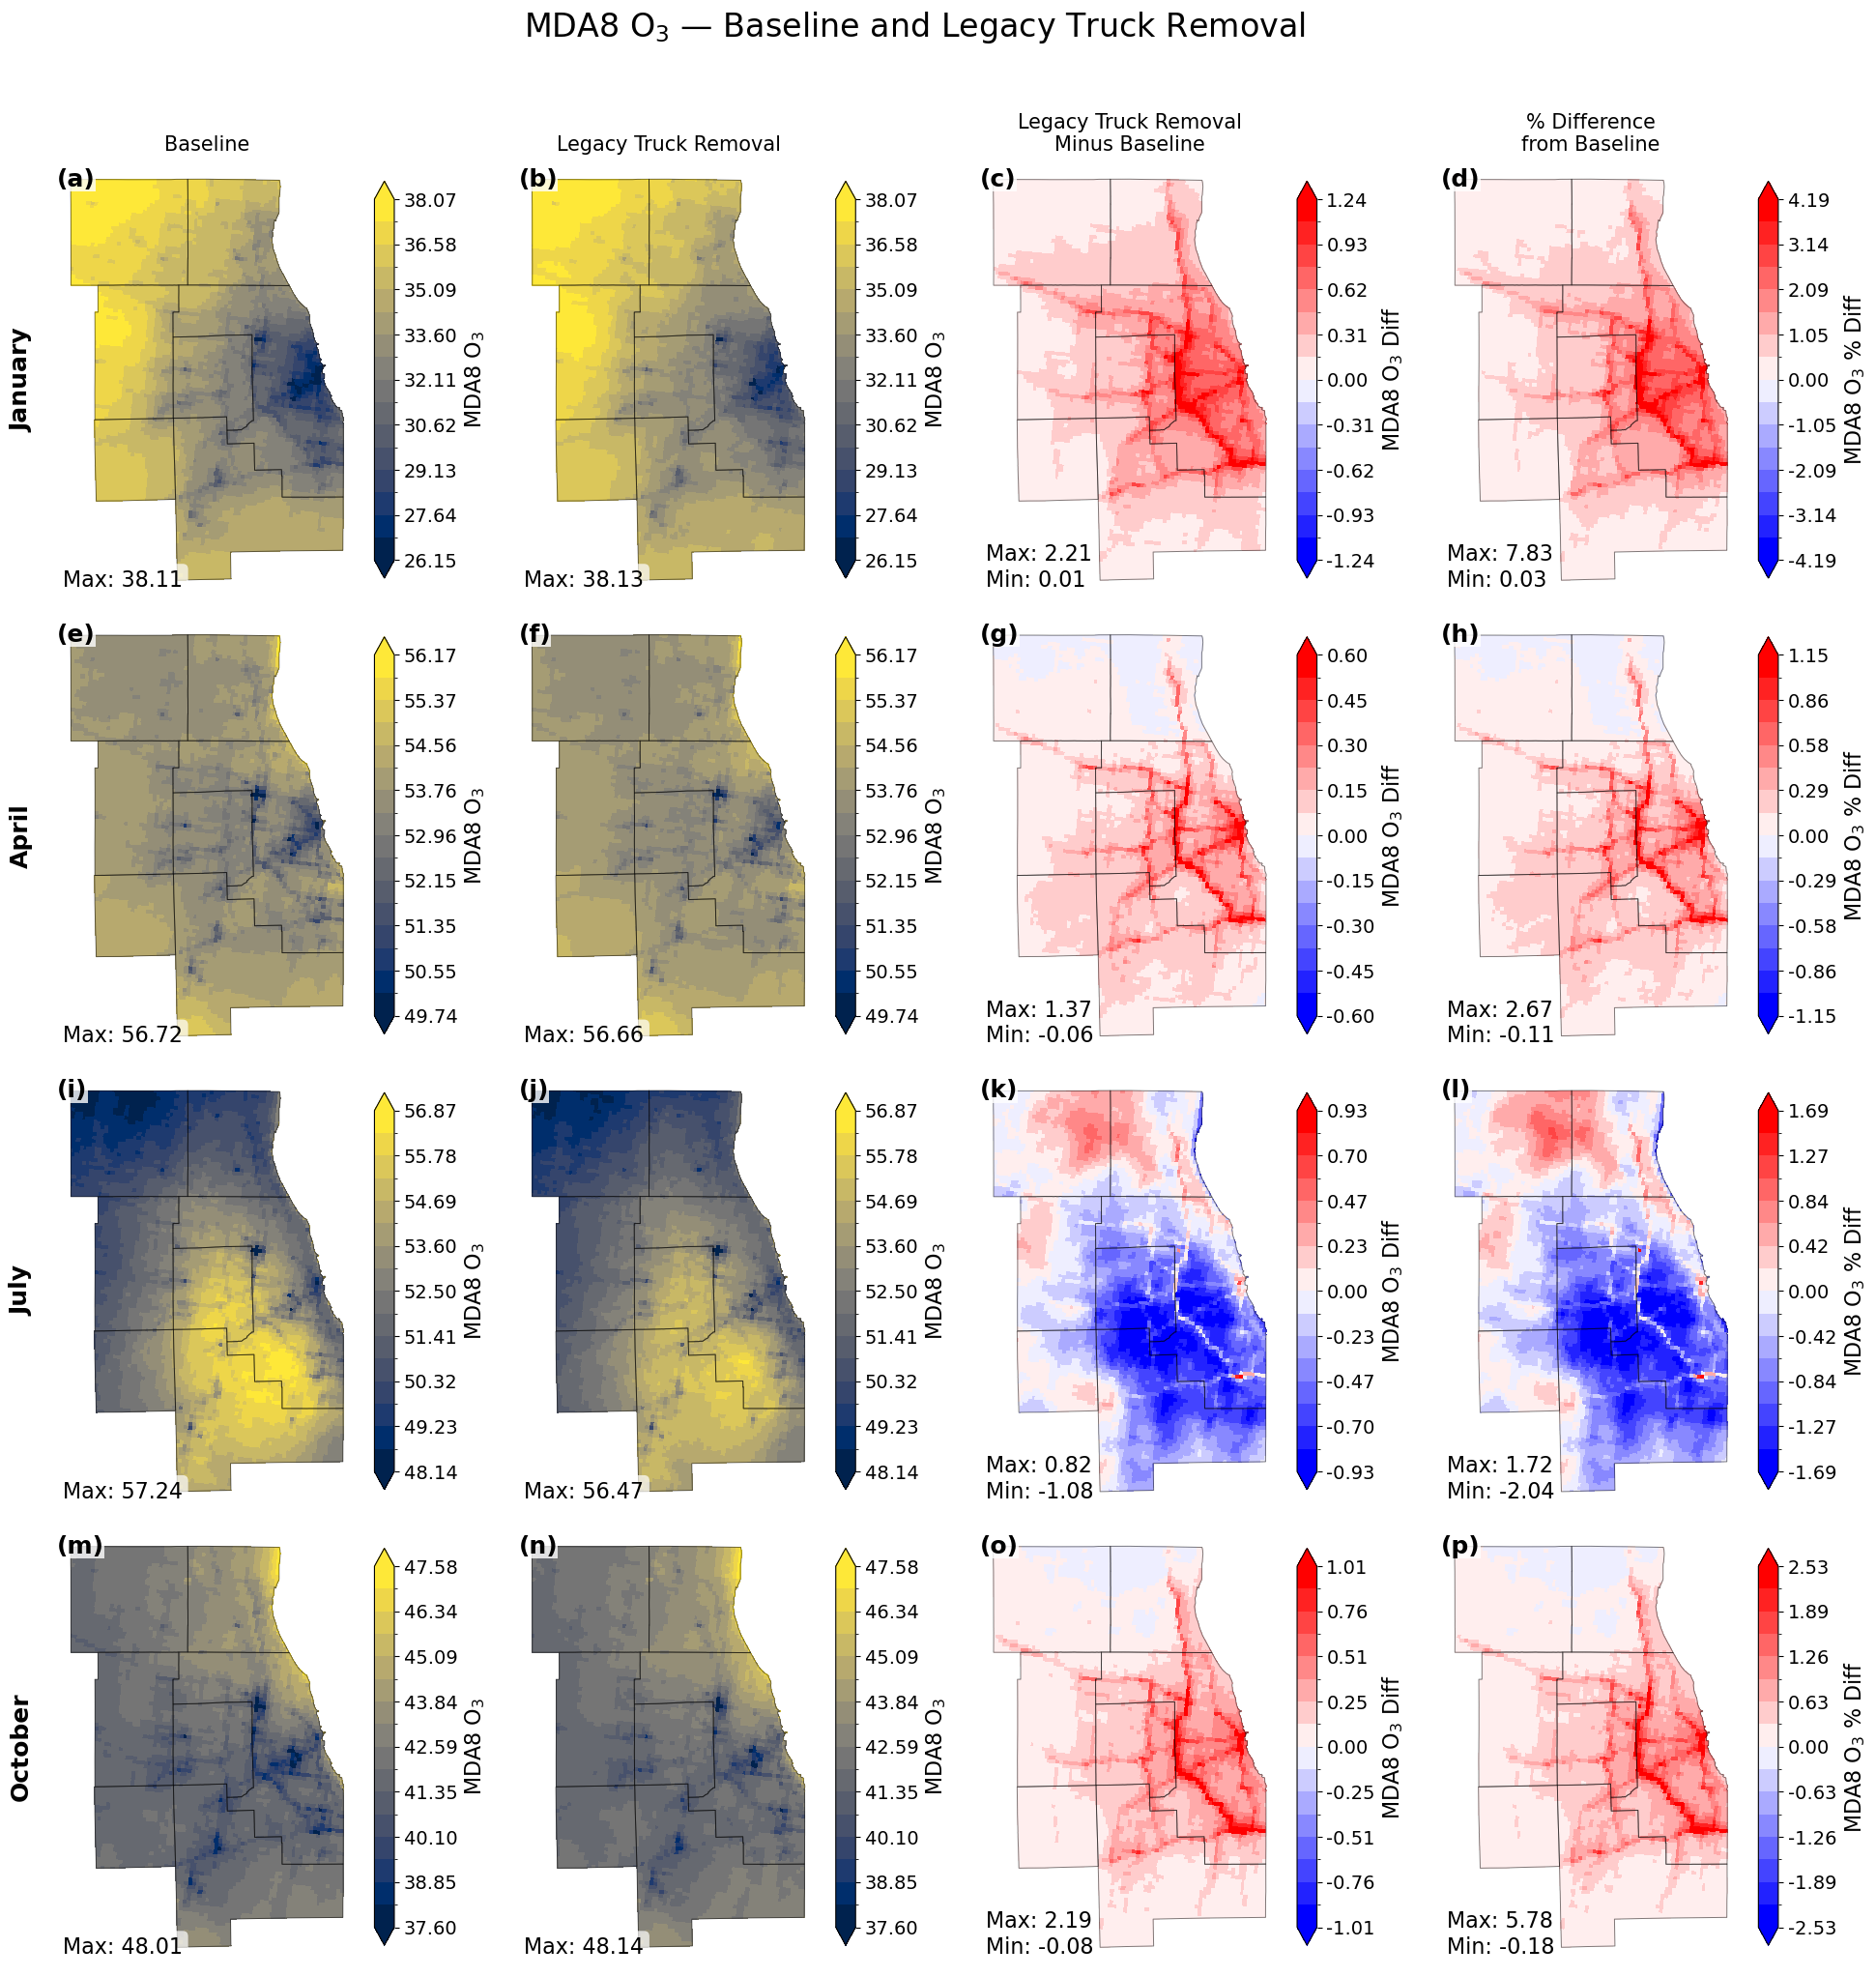

In [10]:
def plot_pollutant_monthly_rows(pol):
    cfg = plot_config[pol]
    col = cfg["column"]

    fig, axs = plt.subplots(
        nrows=len(months),
        ncols=4,
        figsize=(20, 20),
        subplot_kw={"projection": ccrs.PlateCarree()},
    )

    fig.suptitle(
        f"{cfg['title']} — Baseline and Legacy Truck Removal",
        fontsize=24,
        y=1.02,
    )

    for i, month in enumerate(months):
        reference_gdf = monthly_gdfs_by_pol[pol]["reference"][month]
        scenario_gdf = monthly_gdfs_by_pol[pol]["scenario"][month]

        # ------------------------------------------------------------
        # absolute scale shared by default + scenario for this month
        # ------------------------------------------------------------
        vals_all = []

        for gdf in [reference_gdf, scenario_gdf]:
            vals = gdf[col].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            vals_all.append(vals)

        vals_all = np.concatenate(vals_all)

        vmin = np.quantile(vals_all, 0.001)
        vmax = np.quantile(vals_all, 0.999)

        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6

        abs_cmap = ListedColormap(
            plt.cm.get_cmap(cfg["cmap_name"])(np.linspace(0, 1, N_BINS))
        )

        abs_bounds = np.linspace(vmin, vmax, N_BINS + 1)
        abs_norm = BoundaryNorm(abs_bounds, abs_cmap.N)

        # ------------------------------------------------------------
        # difference and percent difference scales for this month
        # ------------------------------------------------------------
        reference_vals = reference_gdf[col].astype(float).to_numpy()
        scenario_vals = scenario_gdf[col].astype(float).to_numpy()

        diff_vals = scenario_vals - reference_vals

        pct_vals = np.where(
            reference_vals != 0,
            (diff_vals / reference_vals) * 100.0,
            np.nan,
        )

        diff_vals_finite = diff_vals[np.isfinite(diff_vals)]
        pct_vals_finite = pct_vals[np.isfinite(pct_vals)]

        diff_lim = np.quantile(np.abs(diff_vals_finite), 0.99)
        pct_lim = np.quantile(np.abs(pct_vals_finite), 0.99)

        if np.isclose(diff_lim, 0):
            diff_lim = 1e-6
        if np.isclose(pct_lim, 0):
            pct_lim = 1e-6

        diff_bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
        pct_bounds = np.linspace(-pct_lim, pct_lim, N_BINS + 1)

        diff_cmap = ListedColormap(
            plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
        )
        pct_cmap = ListedColormap(
            plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
        )

        diff_norm = BoundaryNorm(diff_bounds, diff_cmap.N)
        pct_norm = BoundaryNorm(pct_bounds, pct_cmap.N)

        # ------------------------------------------------------------
        # plotting GeoDataFrames
        # ------------------------------------------------------------
        plot_reference = reference_gdf.copy()
        plot_scenario = scenario_gdf.copy()
        plot_diff = scenario_gdf.copy()
        plot_pct = scenario_gdf.copy()

        plot_reference[pol] = reference_gdf[col].astype(float)
        plot_scenario[pol] = scenario_gdf[col].astype(float)
        plot_diff[pol] = diff_vals
        plot_pct[pol] = pct_vals

        plot_gdfs = [
            plot_reference,
            plot_scenario,
            plot_diff,
            plot_pct,
        ]

        cmaps = [abs_cmap, abs_cmap, diff_cmap, pct_cmap]
        norms = [abs_norm, abs_norm, diff_norm, pct_norm]
        bounds_list = [abs_bounds, abs_bounds, diff_bounds, pct_bounds]

        for j, scen in enumerate(scenario_names):
            ax = axs[i, j]

            panel_label = f"({chr(97 + i * 4 + j)})"

            ax.text(
                0.001,
                0.98,
                panel_label,
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=18,
                fontweight="bold",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.2),
            )

            gdf = plot_gdfs[j]

            gdf.plot(
                column=pol,
                ax=ax,
                cmap=cmaps[j],
                norm=norms[j],
                edgecolor="none",
                antialiased=False,
            )

            cmap_cty.boundary.plot(
                ax=ax,
                color="k",
                alpha=0.5,
                linewidth=0.7,
            )

            if i == 0:
                ax.set_title(scen, fontsize=15)

            if j == 0:
                ax.text(
                    -0.08,
                    0.5,
                    month_labels[month],
                    transform=ax.transAxes,
                    ha="right",
                    va="center",
                    rotation=90,
                    fontsize=18,
                    fontweight="bold",
                )

            ax.set_axis_off()

            sm = plt.cm.ScalarMappable(norm=norms[j], cmap=cmaps[j])
            sm._A = []

            cbar = fig.colorbar(
                sm,
                ax=ax,
                fraction=0.046,
                pad=0.04,
                boundaries=bounds_list[j],
                ticks=bounds_list[j][::2],
                spacing="proportional",
                extend="both",
            )

            cbar.ax.tick_params(labelsize=14)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 3:
                cbar.set_label(f"{cfg['label']} % Diff", fontsize=16)
            elif j == 2:
                cbar.set_label(f"{cfg['label']} Diff", fontsize=16)
            else:
                cbar.set_label(cfg["label"], fontsize=16)

            vals = gdf[pol].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]

            vmax_panel = float(np.nanmax(vals))
            vmin_panel = float(np.nanmin(vals))

            if j in [0, 1]:
                annot_text = f"Max: {vmax_panel:.2f}"
            else:
                annot_text = f"Max: {vmax_panel:.2f}\nMin: {vmin_panel:.2f}"

            ax.text(
                0.02,
                0.02,
                annot_text,
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=16,
                color="black",
                bbox=dict(
                    facecolor="white",
                    alpha=0.7,
                    boxstyle="round,pad=0.25",
                    linewidth=0,
                ),
            )

    plt.tight_layout()
    plt.savefig(f"Fig_Default_zeropre2010s_griddedAirPoll_{pol}_MonthlyRows.png", dpi=500)
    plt.show()
    
for pol in pollutants:
    plot_pollutant_monthly_rows(pol)

<h1> Plot Primary v Secondary PM2.5

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:91: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("plasma")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:128: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:132: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1,

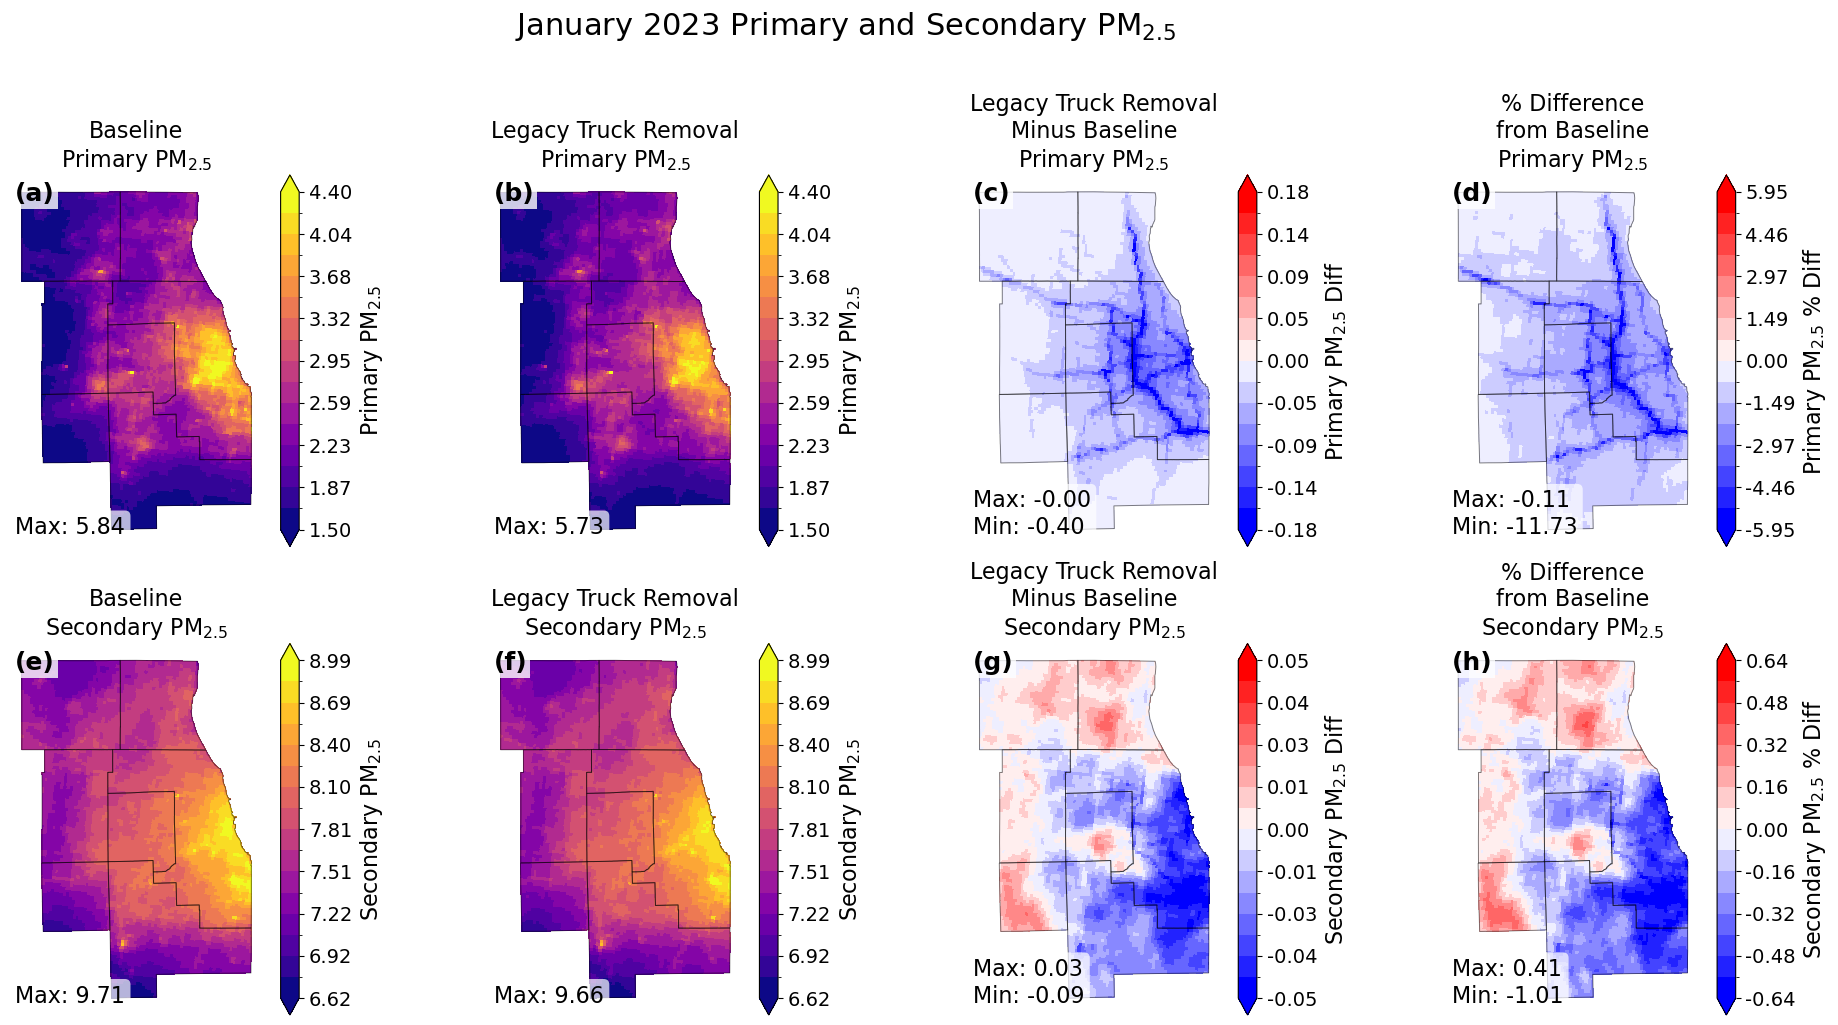

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:91: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("plasma")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:128: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:132: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1,

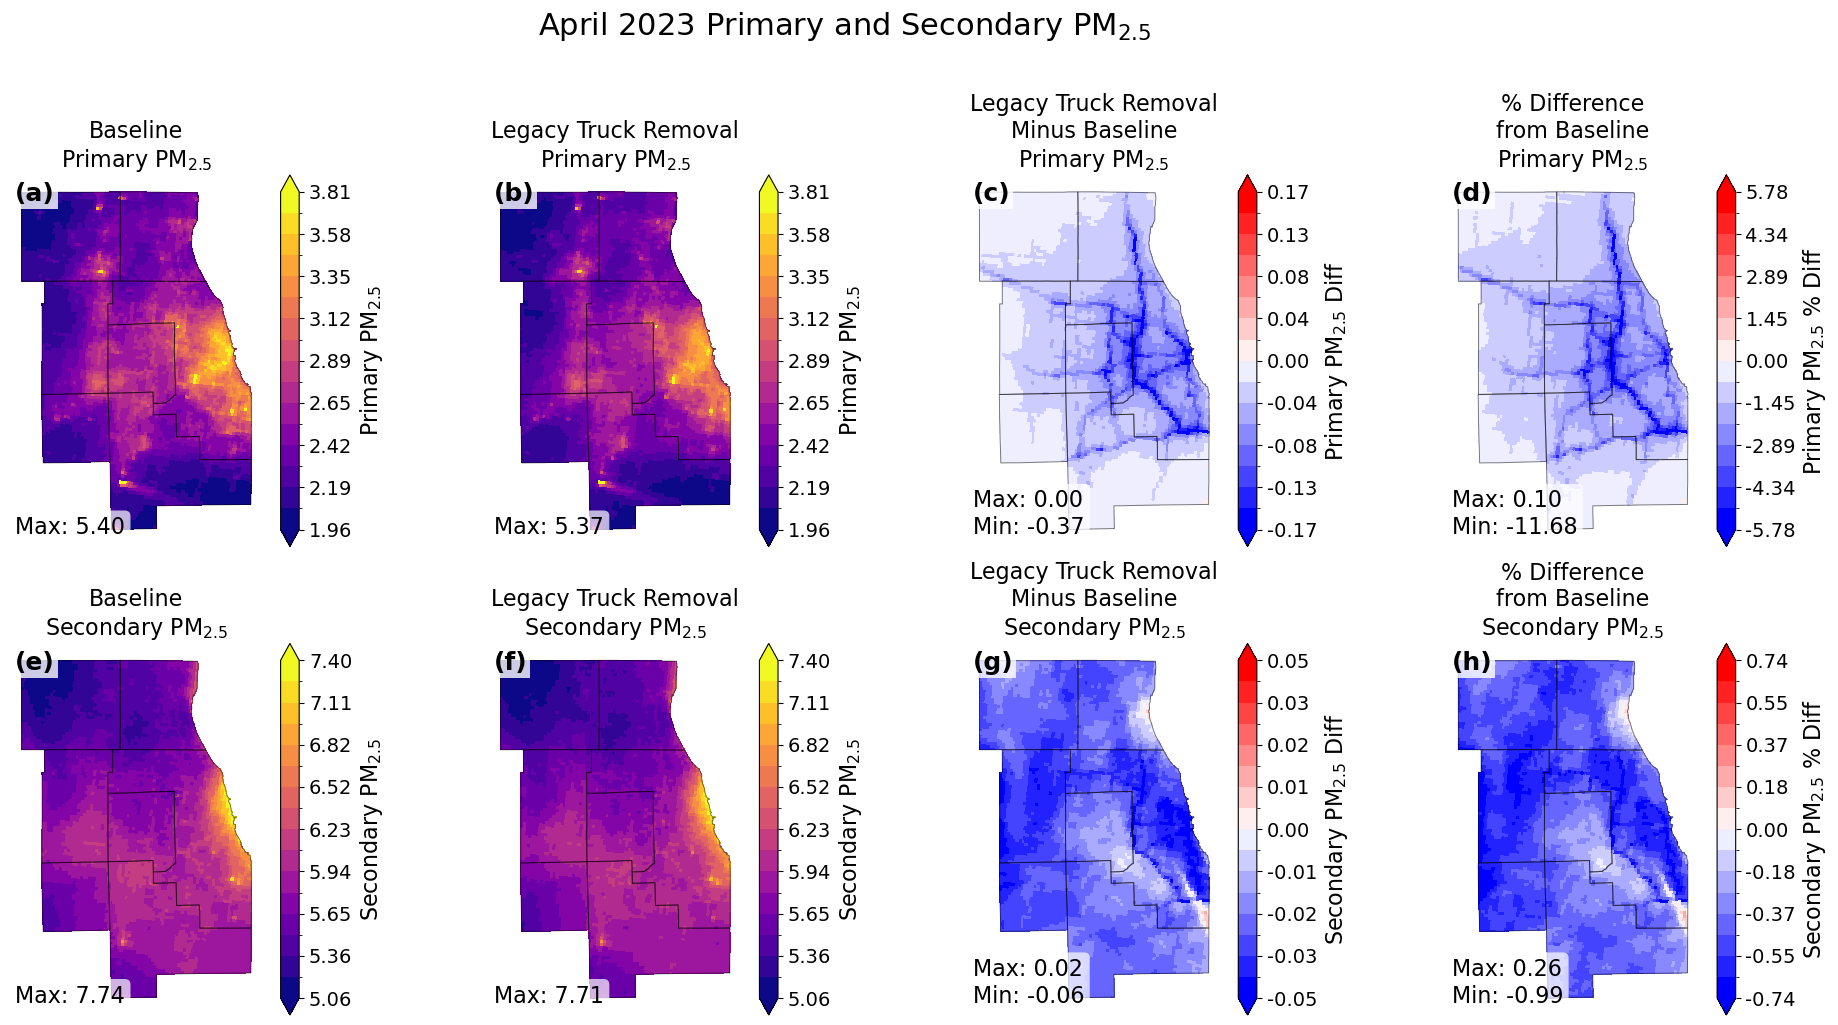

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:91: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("plasma")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:128: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:132: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1,

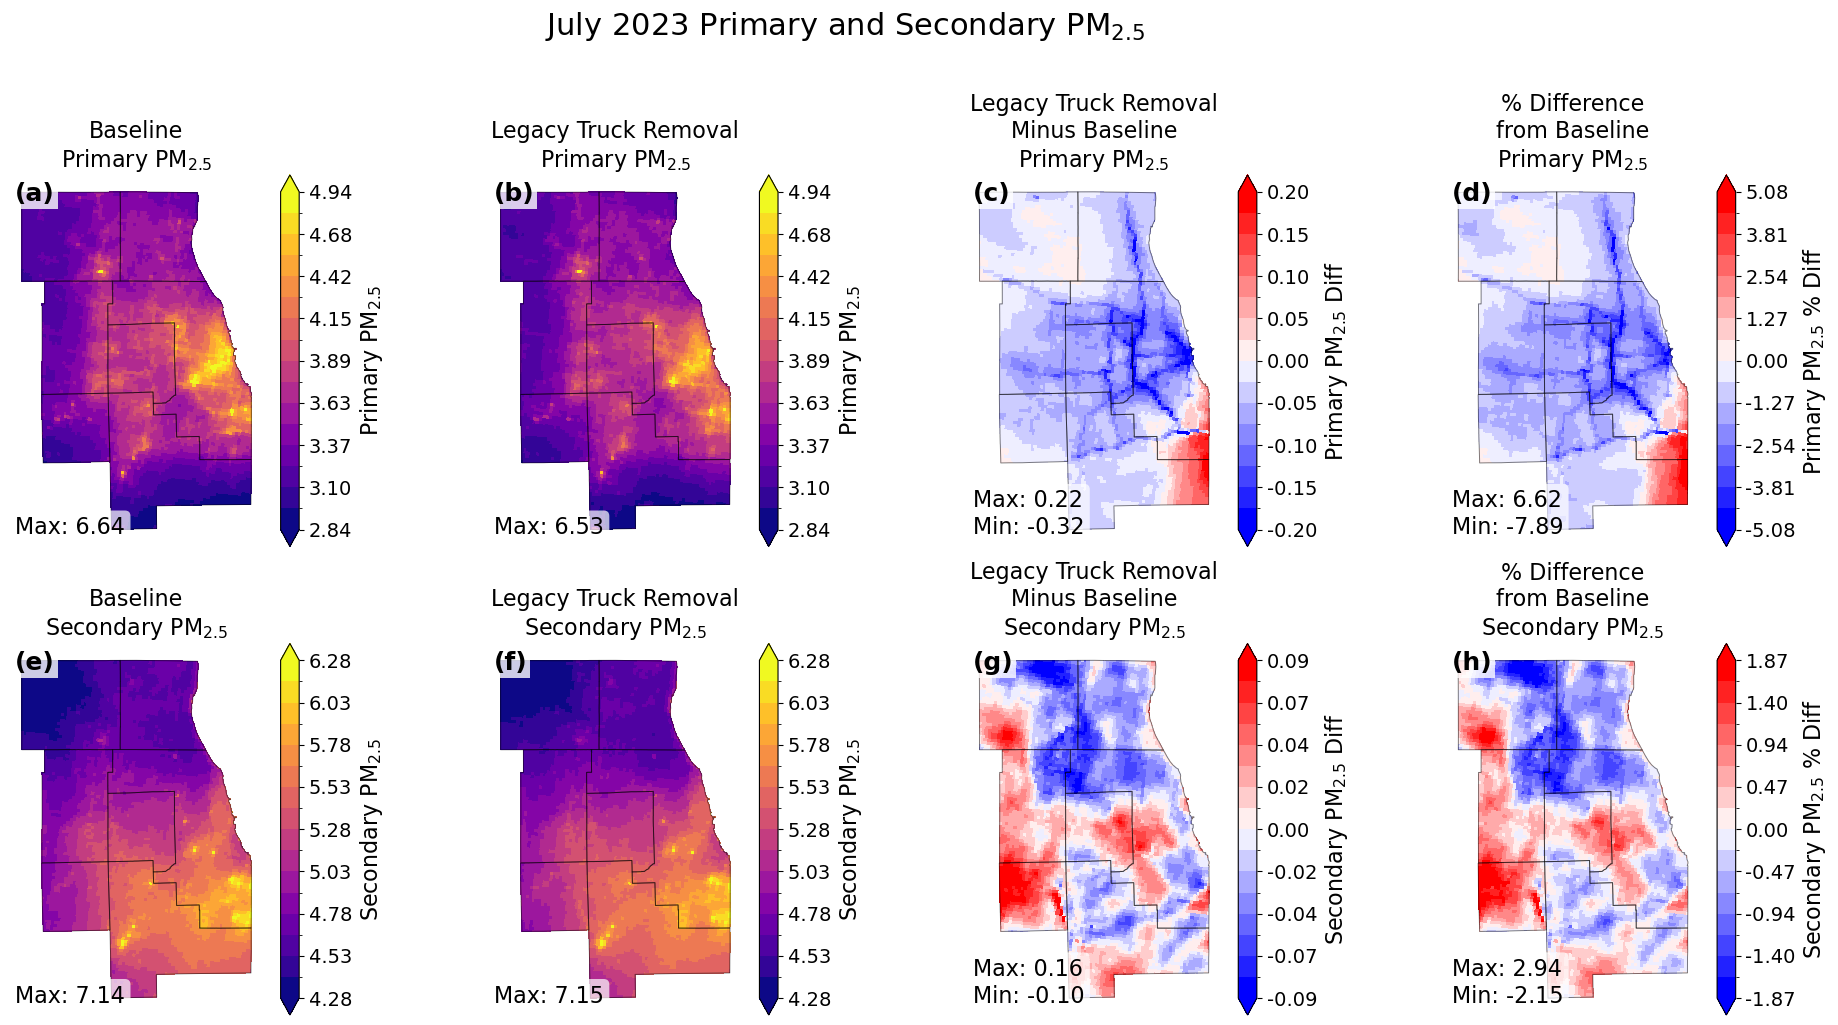

C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:91: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("plasma")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:128: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
C:\Users\x12la\AppData\Local\Temp\ipykernel_1132\369165383.py:132: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.cm.get_cmap("bwr")(np.linspace(0, 1,

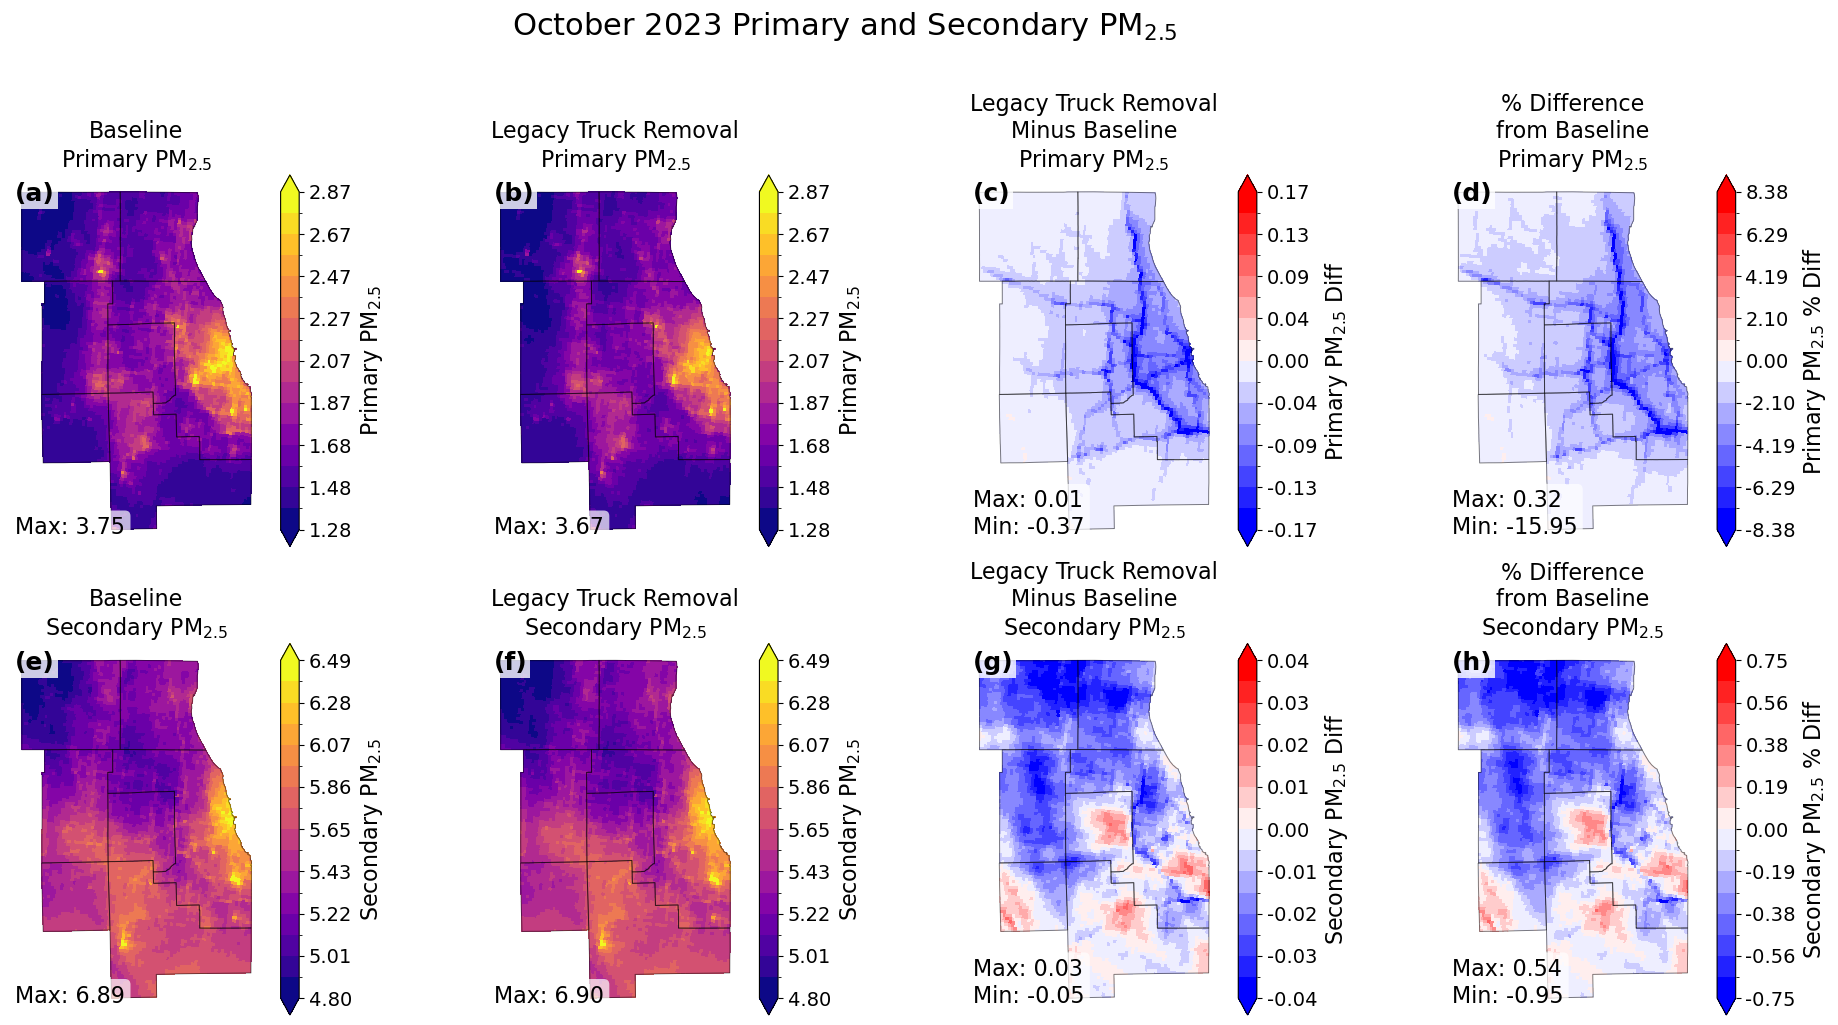

In [11]:
N_BINS = 16

months = ["Jan", "Apr", "Jul", "Oct"]
month_labels = {
    "Jan": "January",
    "Apr": "April",
    "Jul": "July",
    "Oct": "October",
}

primary_pm_species = [
    "APOMIJ",
    "AECIJ",
    "AFEJ",
    "AALJ",
    "ASIJ",
    "ATIJ",
    "ACAJ",
    "AMGJ",
    "AKJ",
    "AMNJ",
]

secondary_pm_species = [
    "ASOMIJ",
    "ASO4IJ",
    "ANO3IJ",
    "ANH4IJ",
]

pm_groups = {
    "PRIMARY_PM25": {
        "species": primary_pm_species,
        "title": "Primary PM$_{2.5}$",
        "label": "Primary PM$_{2.5}$",
    },
    "SECONDARY_PM25": {
        "species": secondary_pm_species,
        "title": "Secondary PM$_{2.5}$",
        "label": "Secondary PM$_{2.5}$",
    },
}

scenario_names = [
    "Baseline",
    "Legacy Truck Removal",
    "Legacy Truck Removal\nMinus Baseline",
    "% Difference\nfrom Baseline",
]

def add_pm_groups(gdf):
    gdf = gdf.copy()

    for pm_name, cfg in pm_groups.items():
        missing = [sp for sp in cfg["species"] if sp not in gdf.columns]

        if missing:
            print(f"Missing {pm_name} species: {missing}")
            gdf[pm_name] = np.nan
        else:
            gdf[pm_name] = gdf[cfg["species"]].astype(float).sum(axis=1)

    return gdf

def plot_monthly_primary_secondary_pm25(month):
    gdf_default = add_pm_groups(cmap_base[month])
    gdf_locus = add_pm_groups(cmap_zeropre2010s[month])

    pollutants = ["PRIMARY_PM25", "SECONDARY_PM25"]

    abs_styles = {}
    diff_styles = {}

    for pol in pollutants:
        vals_all = []

        for gdf in [gdf_default, gdf_locus]:
            vals = gdf[pol].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]
            vals_all.append(vals)

        vals_all = np.concatenate(vals_all)

        vmin = np.quantile(vals_all, 0.001)
        vmax = np.quantile(vals_all, 0.999)

        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6

        cmap_disc = ListedColormap(
            plt.cm.get_cmap("plasma")(np.linspace(0, 1, N_BINS))
        )

        bounds = np.linspace(vmin, vmax, N_BINS + 1)
        norm = BoundaryNorm(bounds, cmap_disc.N)

        abs_styles[pol] = {
            "bounds": bounds,
            "cmap": cmap_disc,
            "norm": norm,
        }

        default_vals = gdf_default[pol].astype(float).to_numpy()
        locus_vals = gdf_locus[pol].astype(float).to_numpy()

        diff_vals = locus_vals - default_vals
        pct_vals = np.where(
            default_vals != 0,
            (diff_vals / default_vals) * 100.0,
            np.nan,
        )

        diff_vals_finite = diff_vals[np.isfinite(diff_vals)]
        pct_vals_finite = pct_vals[np.isfinite(pct_vals)]

        diff_lim = np.quantile(np.abs(diff_vals_finite), 0.99)
        pct_lim = np.quantile(np.abs(pct_vals_finite), 0.99)

        if np.isclose(diff_lim, 0):
            diff_lim = 1e-6
        if np.isclose(pct_lim, 0):
            pct_lim = 1e-6

        diff_bounds = np.linspace(-diff_lim, diff_lim, N_BINS + 1)
        pct_bounds = np.linspace(-pct_lim, pct_lim, N_BINS + 1)

        diff_cmap = ListedColormap(
            plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
        )

        pct_cmap = ListedColormap(
            plt.cm.get_cmap("bwr")(np.linspace(0, 1, N_BINS))
        )

        diff_styles[pol] = {
            "diff_bounds": diff_bounds,
            "diff_cmap": diff_cmap,
            "diff_norm": BoundaryNorm(diff_bounds, diff_cmap.N),
            "pct_bounds": pct_bounds,
            "pct_cmap": pct_cmap,
            "pct_norm": BoundaryNorm(pct_bounds, pct_cmap.N),
        }

    plot_default = gdf_default.copy()
    plot_locus = gdf_locus.copy()
    plot_diff = gdf_locus.copy()
    plot_pct = gdf_locus.copy()

    for pol in pollutants:
        plot_diff[pol] = gdf_locus[pol].astype(float) - gdf_default[pol].astype(float)

        plot_pct[pol] = np.where(
            gdf_default[pol].astype(float) != 0,
            (
                (gdf_locus[pol].astype(float) - gdf_default[pol].astype(float))
                / gdf_default[pol].astype(float)
            )
            * 100.0,
            np.nan,
        )

    scenario_gdfs = {
        scenario_names[0]: plot_default,
        scenario_names[1]: plot_locus,
        scenario_names[2]: plot_diff,
        scenario_names[3]: plot_pct,
    }

    fig, axs = plt.subplots(
        nrows=2,
        ncols=4,
        figsize=(20, 10),
        subplot_kw={"projection": ccrs.PlateCarree()},
    )

    fig.suptitle(
        f"{month_labels[month]} 2023 Primary and Secondary PM$_{{2.5}}$",
        fontsize=22,
        y=1.02,
    )

    for i, pol in enumerate(pollutants):
        for j, scen in enumerate(scenario_names):
            ax = axs[i, j]

            panel_label = f"({chr(97 + i * 4 + j)})"

            ax.text(
                0.02,
                0.98,
                panel_label,
                transform=ax.transAxes,
                fontsize=18,
                fontweight="bold",
                ha="left",
                va="top",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=2),
            )

            gdf = scenario_gdfs[scen]

            if j in [0, 1]:
                style = abs_styles[pol]
                cmap_disc = style["cmap"]
                norm = style["norm"]
                bounds = style["bounds"]
            elif j == 2:
                style = diff_styles[pol]
                cmap_disc = style["diff_cmap"]
                norm = style["diff_norm"]
                bounds = style["diff_bounds"]
            else:
                style = diff_styles[pol]
                cmap_disc = style["pct_cmap"]
                norm = style["pct_norm"]
                bounds = style["pct_bounds"]

            gdf.plot(
                column=pol,
                ax=ax,
                cmap=cmap_disc,
                norm=norm,
                edgecolor="none",
                antialiased=False,
            )

            cmap_cty.boundary.plot(ax=ax, color="k", alpha=0.5, linewidth=0.7)

            ax.set_title(
                f"{scen}\n{pm_groups[pol]['title']}",
                fontsize=16,
            )

            ax.set_axis_off()

            sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap_disc)
            sm._A = []

            cbar = fig.colorbar(
                sm,
                ax=ax,
                fraction=0.046,
                pad=0.04,
                boundaries=bounds,
                ticks=bounds[::2],
                spacing="proportional",
                extend="both",
            )

            cbar.ax.tick_params(labelsize=14)
            cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

            if j == 3:
                cbar.set_label(f"{pm_groups[pol]['label']} % Diff", fontsize=16)
            elif j == 2:
                cbar.set_label(f"{pm_groups[pol]['label']} Diff", fontsize=16)
            else:
                cbar.set_label(pm_groups[pol]["label"], fontsize=16)

            vals = gdf[pol].astype(float).to_numpy()
            vals = vals[np.isfinite(vals)]

            vmax_panel = float(np.nanmax(vals))
            vmin_panel = float(np.nanmin(vals))

            if j in [0, 1]:
                annot_text = f"Max: {vmax_panel:.2f}"
            else:
                annot_text = f"Max: {vmax_panel:.2f}\nMin: {vmin_panel:.2f}"

            ax.text(
                0.02,
                0.02,
                annot_text,
                transform=ax.transAxes,
                ha="left",
                va="bottom",
                fontsize=16,
                color="black",
                bbox=dict(
                    facecolor="white",
                    alpha=0.7,
                    boxstyle="round,pad=0.25",
                    linewidth=0,
                ),
            )

    plt.tight_layout()
    plt.savefig(
        f"Fig_Primary_Secondary_PM25_Default_LOCUS_{month}.png",
        format="png",
        bbox_inches="tight",
        dpi=300,
    )
    plt.show()

for month in months:
    plot_monthly_primary_secondary_pm25(month)